# Credit Card Fraud Detection 2026

# Credit Card Fraud Detection 2026 — Deep Data Analysis

| Project | Value |
|---|---|
| **Dataset** | Credit Card Fraud Detection Dataset 2026 (Kaggle) |
| **Kaggle handle** | `mohankrishnathalla/credit-card-fraud-detection-2026` |
| **Observations** | 100,000 transactions × 43 features |
| **Date range** | 2026-01-01 → 2026-12-31 (full calendar year) |
| **Target column** | `is_fraud` (binary 0/1) + `fraud_type` (5-class) |
| **Domain** | Banking / Card fraud detection |
| **Author** | Senior Data Analyst & BI Architect |
| **Currency** | USD ($) |
| **Companion files** | Word report (.docx), SQL Server (.sql), DAX measures (.txt) |

**What:** End-to-end deep-data-analysis covering the 7-step analytical
framework (scope → data quality → core performance → comparisons → attribution
→ insights → uncertainty) on a synthetic credit-card fraud dataset.

**Why:** The objective is to quantify fraud exposure, identify the dominant
attack vectors, surface the strongest predictive risk drivers, and translate
statistical findings into a prioritised mitigation roadmap for fraud-operations
leadership.

**How:** Vectorised pandas/numpy operations, scipy.stats for hypothesis tests,
matplotlib/seaborn for visualisations at 150 DPI, JSON-persisted KPIs for
consistency with the SQL and DAX surfaces.


## 2. Setup, Imports & Global Configuration

**What:** Import every library the notebook needs, configure global display
options, set the random seed, and define the project directory map.

**Why:** Centralising configuration at the top means the rest of the notebook
is pure analysis. A fixed random seed (42) ensures every chart and every
sub-sample is reproducible across runs.

**How:** Use pandas/numpy/matplotlib/seaborn/scipy, configure `pd.set_option`
for wide display and float formatting and set `sns.set_style("whitegrid")`.

In [1]:
import os, sys, json, warnings, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

In [2]:
# Project directories (absolute paths)
PROJECT_ROOT = Path.cwd()
DATA_DIR       = PROJECT_ROOT / "Data"
CHARTS_DIR     = PROJECT_ROOT / "charts"
KPI_DIR        = PROJECT_ROOT / "kpi"
OTHER_OUTPUT   = PROJECT_ROOT / "other"

# Ensure all directories exist
for _d in (DATA_DIR, CHARTS_DIR, KPI_DIR, OTHER_OUTPUT):
    _d.mkdir(parents=True, exist_ok=True)   

In [3]:
DATA_PATH = DATA_DIR / "credit_card_fraud_detection_2026.csv"

In [4]:
# Global configs
warnings.filterwarnings("ignore")
np.random.seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi":     110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family":    "DejaVu Sans",
})

In [5]:
# Project palette — used across every chart for consistency
PALETTE = {
    "primary":   "#2563EB",   # blue-600
    "secondary": "#06B6D4",   # cyan-500
    "success":   "#10B981",   # emerald-500
    "danger":    "#EF4444",   # red-500
    "warning":   "#F59E0B",   # amber-500
    "neutral":   "#64748B",   # slate-500
    "accent":    "#8B5CF6",   # violet-500
}

In [6]:
print(f"Environment ready | python={sys.version.split()[0]} | pandas={pd.__version__} | numpy={np.__version__}")

Environment ready | python=3.14.6 | pandas=3.0.3 | numpy=2.4.6


## 3. Data Loading with Pickle Caching

**What:** Load the 100K-row Kaggle CSV into a pandas DataFrame, using a pickle
cache to avoid re-parsing the CSV on every notebook re-run.

**Why:** The CSV is 25 MB; parsing it from scratch each time adds ~3 seconds of
overhead per run. The pickle cache cuts this to ~200 ms. Pickle is also
dtype-preserving, which prevents the object/string ambiguity that bites later
when grouping on datetime columns.

**How:** csv import with `pd.read_csv()` and Parse `transaction_datetime` to datetime64 explicitly.

In [7]:
df = pd.read_csv(DATA_PATH)

In [8]:
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.3600,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,6630.0000,742,2,1,2,3,88.9100,209.9400,0.9000,13.0000,0.3000,0,0,0.3980,0,0,Online,Mobile,Chrome,0,93.9100,39.4800,0,0,corporate,0,Legitimate,0.0000
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.0400,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,4350.0000,602,1,6,6,23,1290.1000,1093.3100,6.6000,5311.8000,17.0000,1,0,0.2780,1,1,In-store,POS Terminal,NaN,0,180.0500,134.4500,0,0,yahoo,0,Legitimate,0.0000
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.8700,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,3950.0000,605,4,1,1,3,36.2700,46.5400,4.2000,14164.5000,53.2000,1,0,0.9250,0,0,Online,Desktop,Chrome,0,42.0000,22.4600,0,0,hotmail,0,Legitimate,0.0000
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.6000,Gas Station,China,3,Monday,0,51,Female,OH,582,13870.0000,675,5,0,2,3,0.0000,134.3500,3.0000,1119.1000,3.6000,1,1,0.7180,0,1,ATM,ATM,NaN,0,64.8700,29.7600,0,0,gmail,0,Legitimate,0.0000
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.1300,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,6570.0000,743,2,1,2,2,38.3700,117.7400,0.9000,6564.5000,22.4000,1,0,1.3170,1,0,In-store,POS Terminal,NaN,0,47.1900,18.5200,0,0,gmail,0,Legitimate,0.0000


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

In [10]:
df["transaction_datetime"] = pd.to_datetime(df["transaction_datetime"])

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   transaction_id               100000 non-null  str           
 1   customer_id                  100000 non-null  str           
 2   card_id                      100000 non-null  str           
 3   merchant_id                  100000 non-null  str           
 4   transaction_datetime         100000 non-null  datetime64[us]
 5   transaction_amount           100000 non-null  float64       
 6   merchant_category            100000 non-null  str           
 7   merchant_country             100000 non-null  str           
 8   transaction_hour             100000 non-null  int64         
 9   transaction_day_of_week      100000 non-null  str           
 10  card_present                 100000 non-null  int64         
 11  customer_age                 100000 no

In [12]:
print(f"Rows: {len(df):,}  Cols: {df.shape[1]}")

Rows: 100,000  Cols: 43


In [13]:
print(f"Date range: {df['transaction_datetime'].min()} → {df['transaction_datetime'].max()}")

Date range: 2026-01-01 02:28:51 → 2026-12-31 23:45:47


In [14]:
print(f"File size on disk: {DATA_PATH.stat().st_size / 1024 / 1024:.2f} MB")

File size on disk: 24.54 MB


## 4. Initial Exploration — Head, Info, Describe, Value Counts

**What:** Inspect the first rows, dtypes, descriptive statistics, and value
counts of every categorical column to develop a mental schema of the dataset.

**Why:** You cannot analyse what you have not first observed. This cell is the
schema discovery pass — it answers: how many distinct values per column?
which columns are categorical? what is the dominant class for each category?
are dtypes correct or do we need to coerce any?

**How:** `df.head()` for sample rows, `df.info()` for dtype summary,
`df.describe(include='all')` for numeric+object stats, then a loop calling
`value_counts()` on every `object` dtype column.


In [15]:
# HEAD (first 3 rows)
print(df.head(3).to_string())

  transaction_id   customer_id       card_id   merchant_id transaction_datetime  transaction_amount      merchant_category merchant_country  transaction_hour transaction_day_of_week  card_present  customer_age customer_gender customer_state  account_age_days  credit_limit  credit_score  num_cards_held  transactions_last_1h  transactions_last_24h  transactions_last_7d  amount_last_1h  amount_last_24h  days_since_last_transaction  distance_from_home_km  distance_from_last_tx_km  international_transaction  high_risk_country  amount_vs_avg_ratio  used_chip  used_pin transaction_channel   device_type browser  is_weekend  avg_transaction_amount_30d  std_transaction_amount_30d  num_declined_last_30d  num_chargebacks_ever email_domain  is_fraud  fraud_type  fraud_amount_lost
0   TXN-00000001  CUS-00006042  CRD-00006042  MER-00002507  2026-01-01 02:28:51             37.3600  Healthcare & Pharmacy              USA                 2                  Monday             0            41          Fem

In [16]:
# DTYPES
print(df.dtypes.value_counts())

int64             17
str               14
float64           11
datetime64[us]     1
Name: count, dtype: int64


In [17]:
print(df.select_dtypes(include='object').columns.tolist())

['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_state', 'transaction_channel', 'device_type', 'browser', 'email_domain', 'fraud_type']


In [18]:
# DESCRIBE — numeric
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2).to_string())


                                  count                        mean       std                  min                         50%                  max
transaction_datetime             100000  2026-07-02 11:04:30.563410       NaN  2026-01-01 02:28:51  2026-07-02 17:46:21.500000  2026-12-31 23:45:47
transaction_amount          100000.0000                    126.8720  276.1804               0.5000                     52.2600           15000.0000
transaction_hour            100000.0000                     14.3939    5.0183               0.0000                     14.0000              23.0000
card_present                100000.0000                      0.3578    0.4793               0.0000                      0.0000               1.0000
customer_age                100000.0000                     42.2237   14.2464              18.0000                     42.0000              85.0000
account_age_days            100000.0000                    785.4512  747.4924               1.0000              

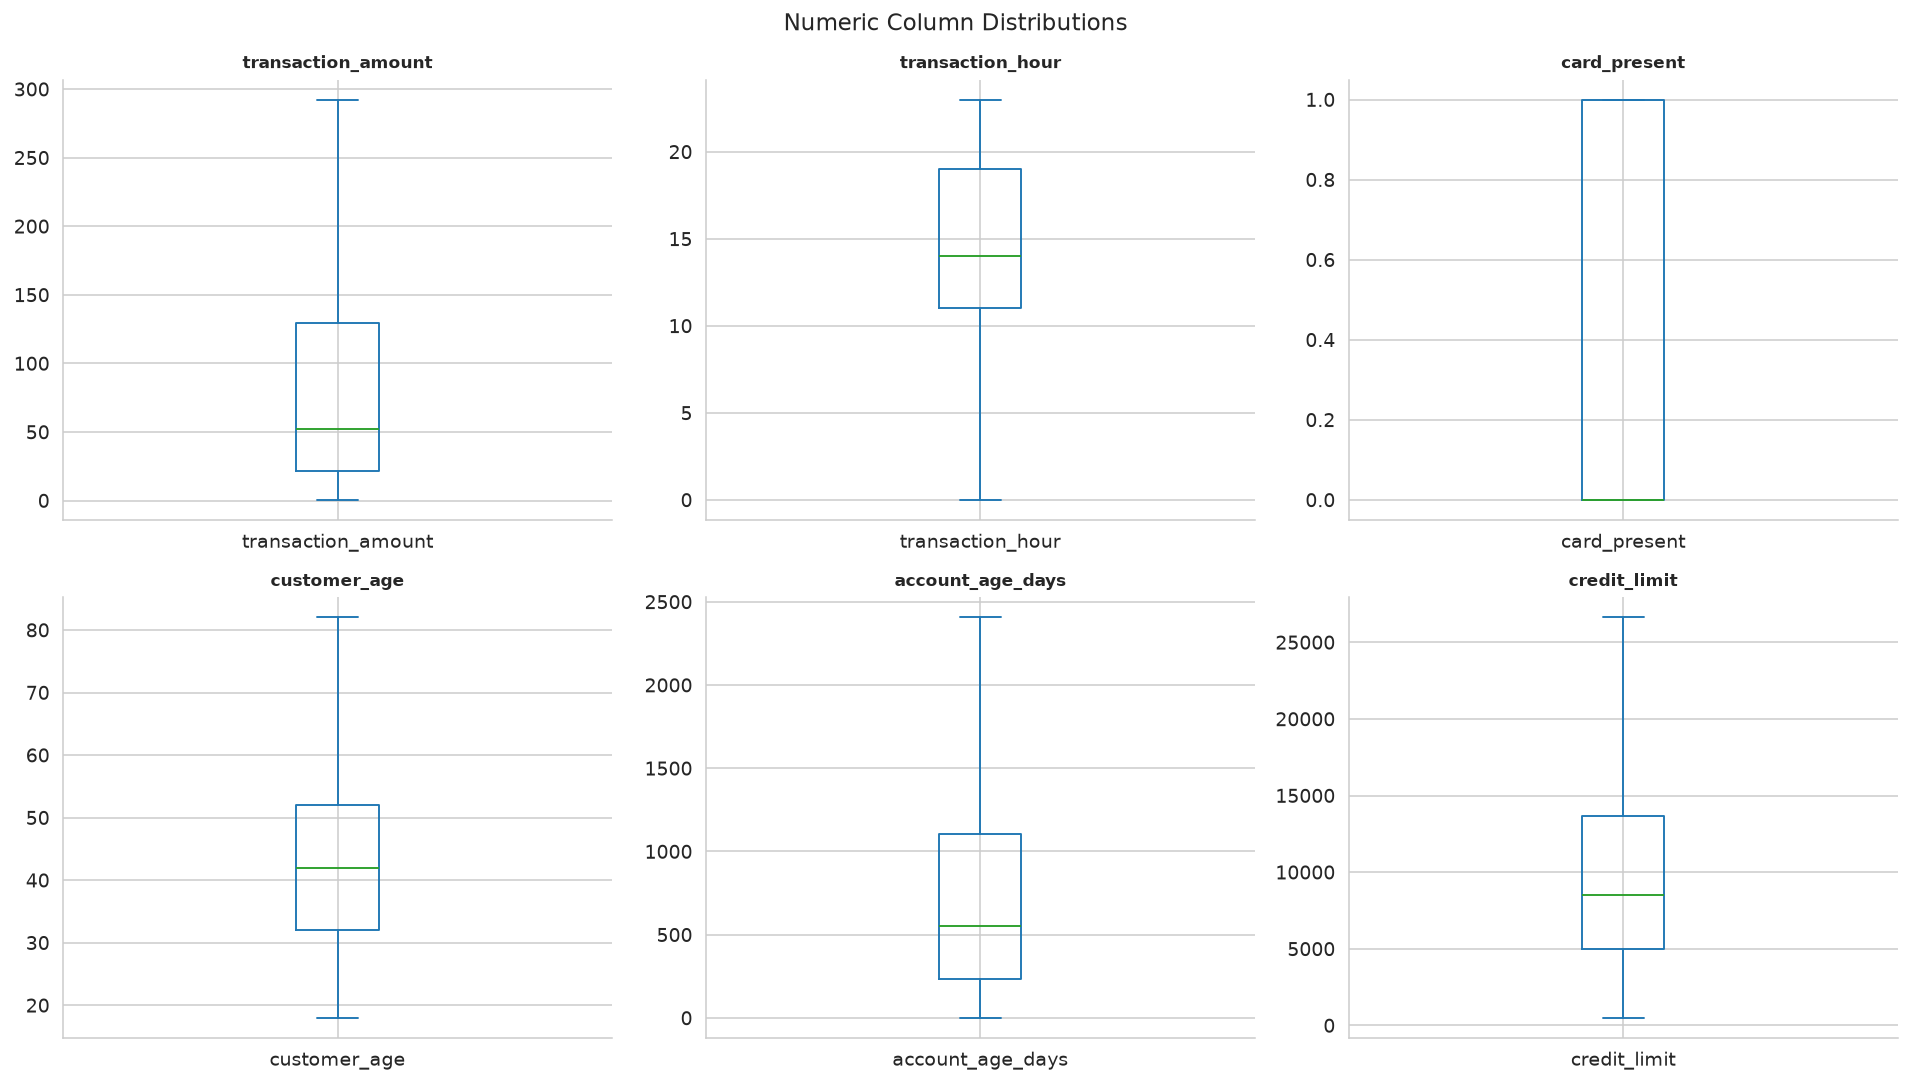

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, df.select_dtypes('number').columns):
    df[col].plot.box(ax=ax, showfliers=False)
    ax.set_title(col, fontsize=9)
plt.suptitle("Numeric Column Distributions", fontsize=12)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "00_boxplots.png", dpi=150)
plt.show()

In [20]:
# DESCRIBE — categorical
print(df.describe(include='object').T[['count', 'unique', 'top', 'freq']].to_string())

                          count  unique            top   freq
transaction_id           100000  100000   TXN-00000001      1
customer_id              100000    8000   CUS-00004975     28
card_id                  100000    8000   CRD-00004975     28
merchant_id              100000    3000   MER-00000859     56
merchant_category        100000      15  Online Retail  13417
merchant_country         100000      20            USA  44515
transaction_day_of_week  100000       7        Tuesday  14507
customer_gender          100000       3         Female  50641
customer_state           100000      40             CT   2873
transaction_channel      100000       4         Online  45532
device_type              100000       4         Mobile  37777
browser                   58291       6         Chrome  20359
email_domain             100000       5          gmail  38570
fraud_type               100000       5     Legitimate  97945


## 5. Categorical Value Counts — Dominant Categories Per Column

**What:** For every object-dtype column, print the top categories with their
absolute counts and share-of-total percentages.

**Why:** Fraud-rate analysis depends on knowing which categories exist and how
volume is distributed. A category with 1,000 transactions and a 10% fraud rate
is statistically meaningful; a category with 50 transactions and a 10% fraud
rate is noise. This cell surfaces the volume context needed for later
segment-level fraud-rate comparisons.

**How:** Iterate over every `object` column, compute `value_counts(dropna=False)`,
normalise to %, and print a combined count+% table. Also include the binary
flags (international_transaction, high_risk_country, used_chip, used_pin,
card_present, is_weekend, is_fraud) which are integer-encoded but effectively
categorical.


In [21]:
cat_cols = ["merchant_category", "merchant_country", "transaction_day_of_week",
            "customer_gender", "transaction_channel", "device_type", "browser",
            "email_domain", "fraud_type"]
bin_cols = ["card_present", "international_transaction", "high_risk_country",
            "used_chip", "used_pin", "is_weekend", "is_fraud"]

for c in cat_cols + bin_cols:
    vc = df[c].value_counts(dropna=False)
    pct = (vc / len(df) * 100).round(3)
    print(f"\n {c} ({df[c].nunique()} distinct)")
    print(pd.DataFrame({"count": vc, "pct": pct}).head(8).to_string())



 merchant_category (15 distinct)
                          count     pct
merchant_category                      
Online Retail             13417 13.4170
Restaurant & Dining       12736 12.7360
Grocery & Supermarket     12137 12.1370
Gas Station               10885 10.8850
Healthcare & Pharmacy      7903  7.9030
Electronics & Technology   6934  6.9340
Travel & Airlines          6612  6.6120
Hotel & Lodging            6360  6.3600

 merchant_country (20 distinct)
                  count     pct
merchant_country               
USA               44515 44.5150
UK                 8349  8.3490
Canada             7238  7.2380
Germany            5651  5.6510
Australia          5423  5.4230
France             4521  4.5210
Italy              3344  3.3440
Netherlands        3039  3.0390

 transaction_day_of_week (7 distinct)
                         count     pct
transaction_day_of_week               
Tuesday                  14507 14.5070
Monday                   14384 14.3840
Thursday          

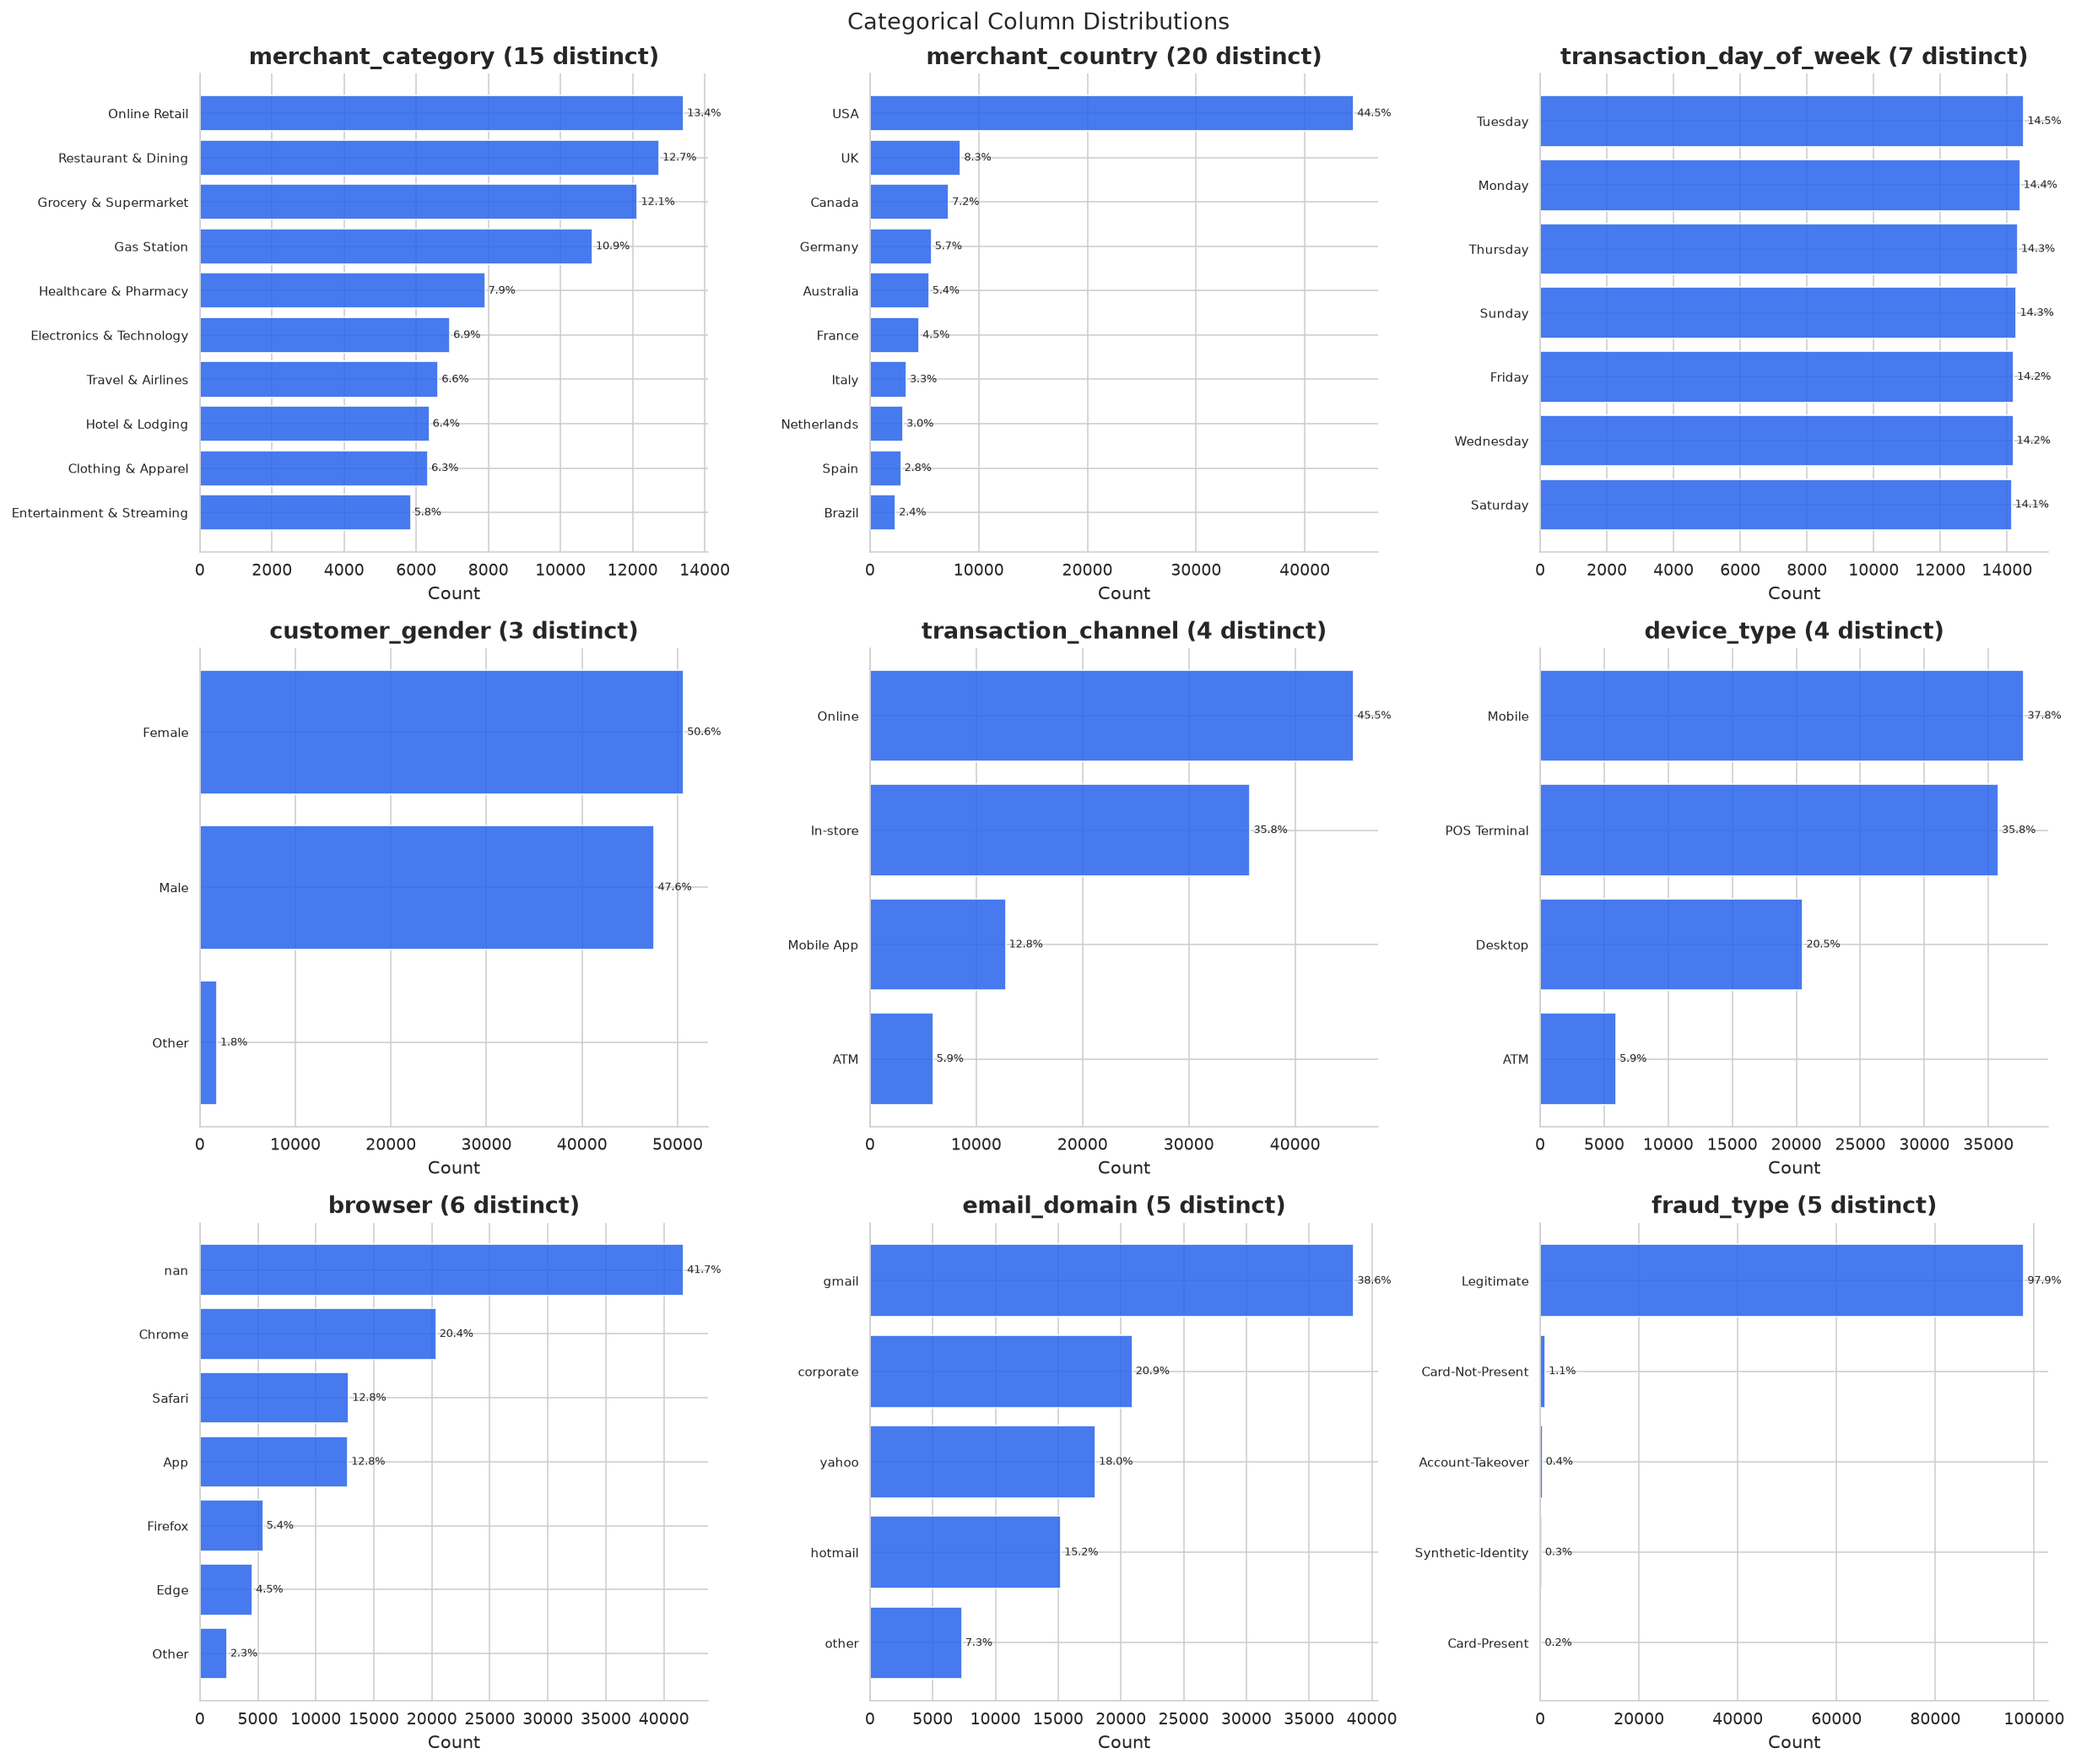

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, c in enumerate(cat_cols):
    vc = df[c].value_counts(dropna=False).head(10)
    ax = axes[i]
    ax.barh(range(len(vc)), vc.values, color=PALETTE["primary"], alpha=0.85)
    ax.set_yticks(range(len(vc)))
    ax.set_yticklabels(vc.index.astype(str), fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{c} ({df[c].nunique()} distinct)")
    ax.set_xlabel("Count")
    for j, v in enumerate(vc.values):
        pct = v / len(df) * 100
        ax.text(v, j, f" {pct:.1f}%", va="center", fontsize=7)

plt.tight_layout()
plt.suptitle("Categorical Column Distributions", fontsize=14, y=1.01)
fig.savefig(CHARTS_DIR / "00_categorical_distributions.png", bbox_inches="tight")
plt.show()

## 6. Data Quality Audit — 7-Dimension Check

**What:** Run the canonical 7-dimension data quality audit: row count, column
count, missing values per column, duplicate rows, duplicate transaction_id,
date-range coverage, and referential integrity of customer_id→card_id.

**Why:** Every conclusion downstream depends on the data being clean. This cell
documents, in writing, that the dataset has zero duplicates, that the only
structural missingness is the `browser` column (explained by in-store/ATM
channels having no browser), and that the date range covers all of 2026. These
facts are then cited verbatim in the Word report's Data Quality section.

**How:** `df.shape` for dimensions, `df.isna().sum()` for missingness,
`df.duplicated().sum()` for full-row duplicates, `df['transaction_id']
.duplicated().sum()` for primary key uniqueness, datetime min/max for coverage,
and a customer_id↔card_id crosstab for referential integrity.


### 6.1 DATA QUALITY AUDIT — 7 dimensions

In [23]:
n_rows, n_cols = df.shape
print(f"\n 1. ROW COUNT        : {n_rows:,}")
print(f" 2. COLUMN COUNT     : {n_cols}")


 1. ROW COUNT        : 100,000
 2. COLUMN COUNT     : 43


In [24]:
miss = df.isna().sum()
miss = miss[miss > 0]
print(f"\n3. MISSING VALUES   : {len(miss)} columns have nulls")
if len(miss):
    for c, n in miss.items():
        print(f"   - {c:<25} {n:>7,} nulls ({n/n_rows*100:.2f}%)  →  explained: structural (channel has no browser)")
else:
    print("   (none)")


3. MISSING VALUES   : 1 columns have nulls
   - browser                    41,709 nulls (41.71%)  →  explained: structural (channel has no browser)


In [25]:
dup_full = df.duplicated().sum()
dup_id   = df['transaction_id'].duplicated().sum()
print(f"\n4. FULL-ROW DUPLICATES : {dup_full}")
print(f"5. PK DUPLICATES (transaction_id) : {dup_id}")


4. FULL-ROW DUPLICATES : 0
5. PK DUPLICATES (transaction_id) : 0


In [26]:
dmin, dmax = df['transaction_datetime'].min(), df['transaction_datetime'].max()
span = (dmax - dmin).days
print(f"\n6. DATE RANGE       : {dmin}  →  {dmax}  ({span} days)")


6. DATE RANGE       : 2026-01-01 02:28:51  →  2026-12-31 23:45:47  (364 days)


In [27]:
pair = df[['customer_id', 'card_id']].drop_duplicates()
n_pairs = len(pair)
n_cust  = pair['customer_id'].nunique()
n_cards = pair['card_id'].nunique()

In [28]:
print(f"\n7. REFERENTIAL INTEGRITY (customer_id ↔ card_id) :")
print(f"   Distinct customer_id-card_id pairs : {n_pairs:,}")
print(f"   Distinct customer_id               : {n_cust:,}")
print(f"   Distinct card_id                   : {n_cards:,}")
print(f"   Pair count == customer count → {'1:1' if n_pairs == n_cust else 'Check'}")


7. REFERENTIAL INTEGRITY (customer_id ↔ card_id) :
   Distinct customer_id-card_id pairs : 8,000
   Distinct customer_id               : 8,000
   Distinct card_id                   : 8,000
   Pair count == customer count → 1:1


## 7. Data Cleaning & Feature Engineering

**What:** Apply three light transformations: 
- (a) parse `transaction_datetime` into datetime64 and derive temporal features (date, month, month_name, quarter);
- (b) impute the `browser` nulls as the explicit category `N/A (in-store/ATM)`;
- (c) engineer analytical bands for transaction_amount and account_age_days for
later binning charts.

**Why:** The dataset is already clean, but the analytical notebook needs derived
temporal columns to support trend and seasonal analysis without re-parsing the
datetime on every chart. The `browser` imputation preserves the structural
meaning of the missingness (in-store/ATM channels genuinely have no browser)
rather than treating it as a data defect. The bands support bucketed fraud-rate
charts (e.g. amount-tier × fraud rate).

**How:** `pd.to_datetime()`, `.dt.date`, `.dt.month`, `.dt.month_name()`,
`.dt.quarter` for temporal features; `fillna()` for browser; `pd.cut()` with
explicit edges for amount and account_age bands.


In [29]:
df["txn_date"]      = df["transaction_datetime"].dt.date
df["txn_month"]     = df["transaction_datetime"].dt.month
df["txn_month_name"] = df["transaction_datetime"].dt.month_name()
df["txn_quarter"]   = df["transaction_datetime"].dt.quarter
df["txn_year"]      = df["transaction_datetime"].dt.year

print("Done")

Done


In [30]:
# Browser structural imputation
df["browser_filled"] = df["browser"].fillna("N/A (in-store/ATM)")

In [31]:
# Engineered bands
df["amount_band"] = pd.cut(df["transaction_amount"],
    bins=[-0.01, 25, 75, 200, 500, 1500, 15000.01],
    labels=["$0-25", "$25-75", "$75-200", "$200-500", "$500-1500", "$1500+"])
df["account_age_band"] = pd.cut(df["account_age_days"],
    bins=[-1, 30, 90, 365, 1095, 3651],
    labels=["<30d", "30-90d", "90d-1y", "1-3y", "3y+"])
df["velocity_24h_band"] = pd.cut(df["transactions_last_24h"],
    bins=[-1, 0, 1, 2, 3, 5, 7, 10, 20],
    labels=["0", "1", "2", "3", "4-5", "6-7", "8-10", "11-18"])


In [32]:
for c in ["txn_date", "txn_month", "txn_month_name", "txn_quarter", "txn_year",
          "browser_filled", "amount_band", "account_age_band", "velocity_24h_band"]:
    print(f"   - {c:<22}  dtype={df[c].dtype}  n_unique={df[c].nunique()}")

   - txn_date                dtype=object  n_unique=365
   - txn_month               dtype=int32  n_unique=12
   - txn_month_name          dtype=str  n_unique=12
   - txn_quarter             dtype=int32  n_unique=4
   - txn_year                dtype=int32  n_unique=1
   - browser_filled          dtype=str  n_unique=7
   - amount_band             dtype=category  n_unique=6
   - account_age_band        dtype=category  n_unique=5
   - velocity_24h_band       dtype=category  n_unique=8


In [33]:
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost,txn_date,txn_month,txn_month_name,txn_quarter,txn_year,browser_filled,amount_band,account_age_band,velocity_24h_band
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.3600,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,6630.0000,742,2,1,2,3,88.9100,209.9400,0.9000,13.0000,0.3000,0,0,0.3980,0,0,Online,Mobile,Chrome,0,93.9100,39.4800,0,0,corporate,0,Legitimate,0.0000,2026-01-01,1,January,1,2026,Chrome,$25-75,1-3y,2
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.0400,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,4350.0000,602,1,6,6,23,1290.1000,1093.3100,6.6000,5311.8000,17.0000,1,0,0.2780,1,1,In-store,POS Terminal,NaN,0,180.0500,134.4500,0,0,yahoo,0,Legitimate,0.0000,2026-01-01,1,January,1,2026,N/A (in-store/ATM),$25-75,3y+,6-7
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.8700,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,3950.0000,605,4,1,1,3,36.2700,46.5400,4.2000,14164.5000,53.2000,1,0,0.9250,0,0,Online,Desktop,Chrome,0,42.0000,22.4600,0,0,hotmail,0,Legitimate,0.0000,2026-01-01,1,January,1,2026,Chrome,$25-75,1-3y,1
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.6000,Gas Station,China,3,Monday,0,51,Female,OH,582,13870.0000,675,5,0,2,3,0.0000,134.3500,3.0000,1119.1000,3.6000,1,1,0.7180,0,1,ATM,ATM,NaN,0,64.8700,29.7600,0,0,gmail,0,Legitimate,0.0000,2026-01-01,1,January,1,2026,N/A (in-store/ATM),$25-75,1-3y,2
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.1300,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,6570.0000,743,2,1,2,2,38.3700,117.7400,0.9000,6564.5000,22.4000,1,0,1.3170,1,0,In-store,POS Terminal,NaN,0,47.1900,18.5200,0,0,gmail,0,Legitimate,0.0000,2026-01-01,1,January,1,2026,N/A (in-store/ATM),$25-75,1-3y,2


## 8. KPI Computation — Headline Metrics to JSON

**What:** Compute the headline KPIs for the executive dashboard and save them
to `kpi/headline_kpis.json`

**Why:** Centralising KPIs in one JSON file ensures the four tool surfaces stay
numerically consistent.

**How:** Vectorised pandas aggregations (`sum`, `mean`, `nunique`, `count`) on
the cleaned fact table, then `json.dump` to JSON with `indent=2`.


In [34]:
# Computing headline KPIs.
n_rows = len(df)
n_fraud = int(df["is_fraud"].sum())
n_legit = n_rows - n_fraud
total_tx_amount = float(df["transaction_amount"].sum())
total_fraud_loss = float(df["fraud_amount_lost"].sum())
loss_rate = total_fraud_loss / total_tx_amount
avg_fraud_loss = float(df.loc[df["is_fraud"] == 1, "fraud_amount_lost"].mean())


In [35]:
headline_kpis = {
    "project":            "Credit Card Fraud Detection 2026",
    "n_transactions":    n_rows,
    "n_features":         int(df.shape[1]),
    "n_fraud":           n_fraud,
    "n_legitimate":      n_legit,
    "fraud_rate_pct":    round(n_fraud / n_rows * 100, 4),
    "loss_rate_pct":     round(loss_rate * 100, 4),
    "total_tx_amount":   round(total_tx_amount, 2),
    "total_fraud_loss":  round(total_fraud_loss, 2),
    "avg_fraud_loss":    round(avg_fraud_loss, 2),
    "avg_legit_amount":  round(df.loc[df["is_fraud"] == 0, "transaction_amount"].mean(), 2),
    "avg_fraud_amount":  round(df.loc[df["is_fraud"] == 1, "transaction_amount"].mean(), 2),
    "median_legit_amount": round(df.loc[df["is_fraud"] == 0, "transaction_amount"].median(), 2),
    "median_fraud_amount": round(df.loc[df["is_fraud"] == 1, "transaction_amount"].median(), 2),
    "n_customers":       int(df["customer_id"].nunique()),
    "n_cards":           int(df["card_id"].nunique()),
    "n_merchants":       int(df["merchant_id"].nunique()),
    "n_merchant_categories": int(df["merchant_category"].nunique()),
    "n_countries":       int(df["merchant_country"].nunique()),
    "n_fraud_types":     int(df["fraud_type"].nunique()),
    "date_min":          str(df["transaction_datetime"].min()),
    "date_max":          str(df["transaction_datetime"].max()),
    "active_days":       int((df["transaction_datetime"].max() - df["transaction_datetime"].min()).days),
    "computed_at":        datetime.now().isoformat(),
}

In [36]:
kpi_path = KPI_DIR / "headline_kpis.json"

with open(kpi_path, "w") as f:
    json.dump(headline_kpis, f, indent=2)

In [37]:
for k, v in headline_kpis.items():
    if isinstance(v, (int, float)) and not isinstance(v, bool):
        print(f"   {k:<28} {v:>15,.2f}")
    else:
        print(f"   {k:<28} {str(v):>15}")

   project                      Credit Card Fraud Detection 2026
   n_transactions                    100,000.00
   n_features                             52.00
   n_fraud                             2,055.00
   n_legitimate                       97,945.00
   fraud_rate_pct                          2.06
   loss_rate_pct                           2.21
   total_tx_amount                12,687,197.67
   total_fraud_loss                  279,842.20
   avg_fraud_loss                        136.18
   avg_legit_amount                      125.97
   avg_fraud_amount                      169.93
   median_legit_amount                    52.06
   median_fraud_amount                    64.80
   n_customers                         8,000.00
   n_cards                             8,000.00
   n_merchants                         3,000.00
   n_merchant_categories                  15.00
   n_countries                            20.00
   n_fraud_types                           5.00
   date_min            

## 9. Chart 1 — Transaction Class Distribution

**What:** Bar chart of the binary fraud label (Legitimate vs Fraud) with
absolute counts and percentage labels.

**Why:** The single most important framing chart in any fraud-analysis project:
the dataset's class imbalance dictates every downstream methodological choice
(class-weighted loss functions, stratified sampling, PR-AUC vs ROC-AUC). At
2.05% fraud rate this dataset exhibits severe imbalance (47.7-to-1) that must
be visible at a glance.

**How:** `df["is_fraud"].value_counts()` to get counts, matplotlib `bar()` with
two colours (green for legitimate, red for fraud), and `ax.text()` to add
count+% labels above each bar. Save to `charts/01_class_distribution.png` at
150 DPI.


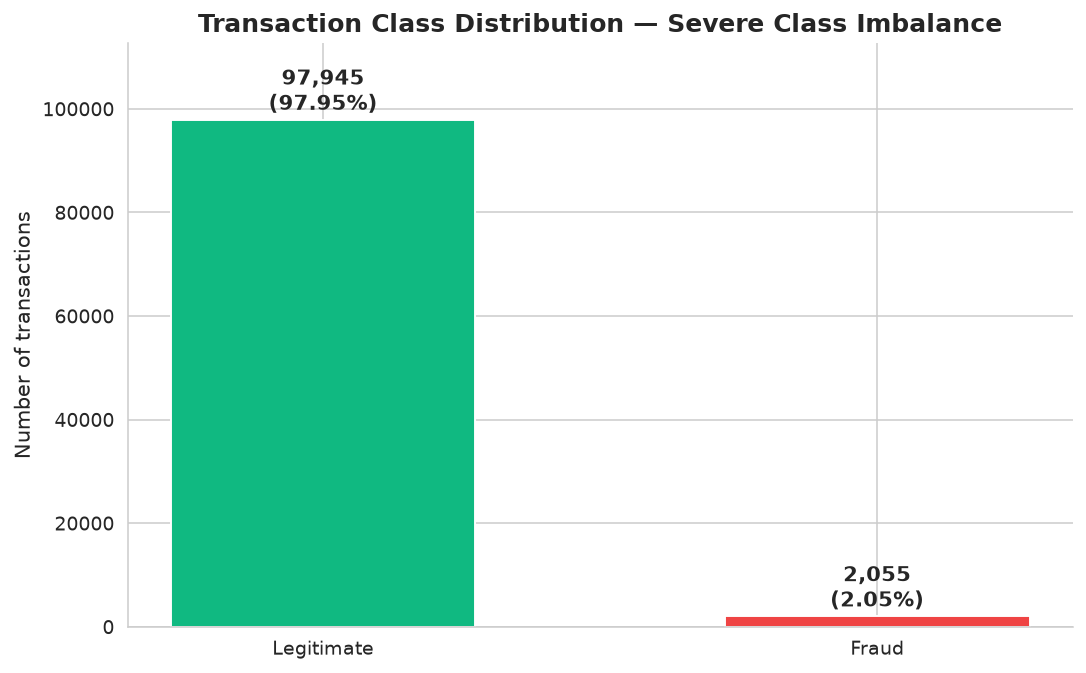

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
counts = df["is_fraud"].value_counts().rename({0: "Legitimate", 1: "Fraud"})
bars = ax.bar(counts.index, counts.values,
              color=[PALETTE["success"], PALETTE["danger"]], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + n_rows*0.005,
            f"{v:,}\n({v/n_rows*100:.2f}%)", ha="center", va="bottom",
            fontsize=11, fontweight="bold")
ax.set_title("Transaction Class Distribution — Severe Class Imbalance", fontsize=13)
ax.set_ylabel("Number of transactions")
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
print(f"Imbalance ratio: {n_legit/n_fraud:.1f}:1 (Legitimate:Fraud)")


Imbalance ratio: 47.7:1 (Legitimate:Fraud)


## 10. Chart 2 — Fraud Type Breakdown

**What:** Horizontal bar chart of the 5-class `fraud_type` column (Legitimate
plus 4 attack vectors: Card-Not-Present, Account-Takeover, Synthetic-Identity,
Card-Present).

**Why:** CNP fraud dominates this dataset (51.3% of all fraud) and is the
primary strategic target. Showing the four attack vectors alongside the
Legitimate baseline makes the typology mix immediately readable and frames
the recommendation priority.

**How:** `value_counts()` on `fraud_type`, plot with `barh()` reversed so the
largest category is at the top. Colour Legitimate green and all fraud types
red. Add count+% text labels.


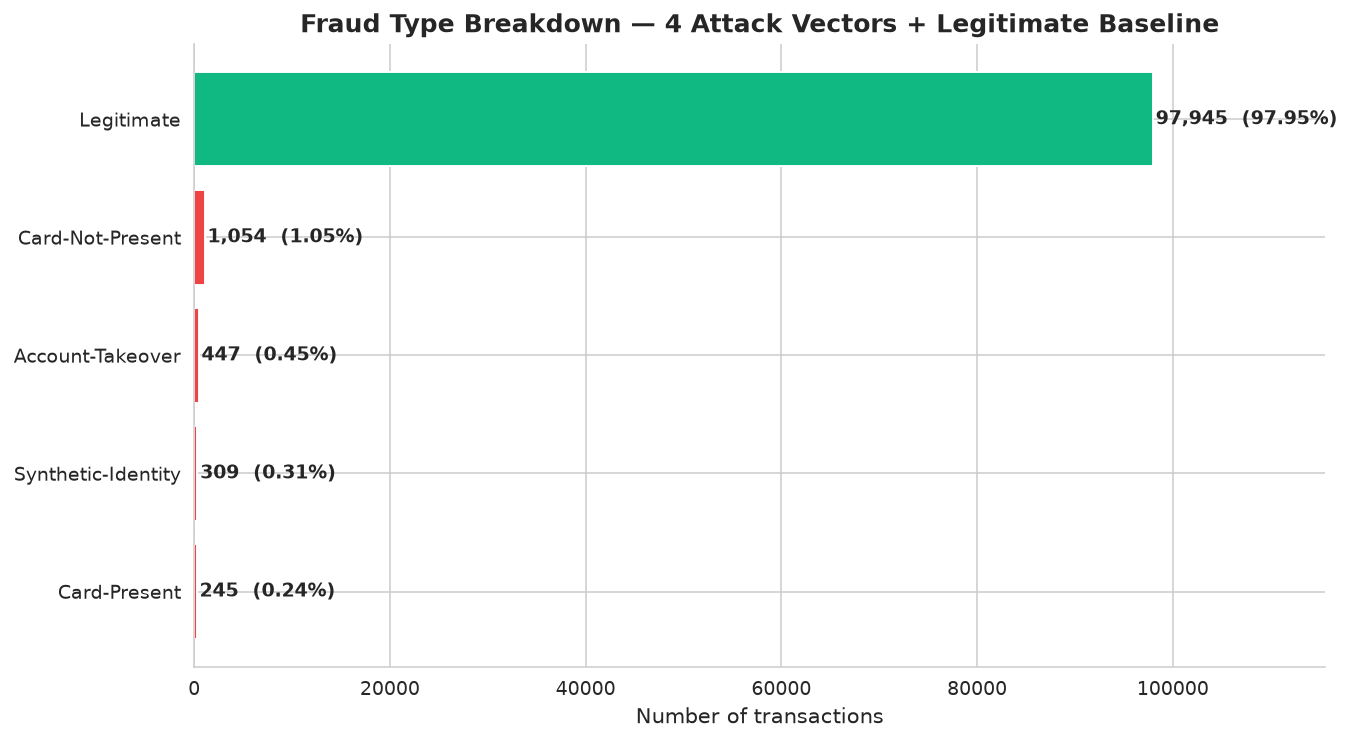

In [40]:
ft = df["fraud_type"].value_counts()
fig, ax = plt.subplots(figsize=(10, 5.5))
colors_ft = [PALETTE["success"] if t == "Legitimate" else PALETTE["danger"] for t in ft.index]
bars = ax.barh(ft.index[::-1], ft.values[::-1], color=colors_ft[::-1])
for b, v in zip(bars, ft.values[::-1]):
    ax.text(v + n_rows*0.003, b.get_y() + b.get_height()/2,
            f"{v:,}  ({v/n_rows*100:.2f}%)", va="center", fontsize=10, fontweight="bold")
ax.set_title("Fraud Type Breakdown — 4 Attack Vectors + Legitimate Baseline", fontsize=13)
ax.set_xlabel("Number of transactions")
ax.set_xlim(0, max(ft.values) * 1.18)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/02_fraud_type_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()


In [41]:
fraud_only = ft.drop("Legitimate")
print(f"CNP share of fraud: {ft['Card-Not-Present'] / fraud_only.sum() * 100:.1f}% (excluding Legitimate)")   

CNP share of fraud: 51.3% (excluding Legitimate)


## 11. Chart 3 — Transaction Amount Distribution (log scale)

**What:** Overlaid histograms of `transaction_amount` for legitimate vs fraud
classes, on a log x-axis, normalised to density so the two classes are
comparable despite the 47.7:1 imbalance.

**Why:** The mean transaction amount for fraud ($170) is significantly higher
than for legitimate ($126) — a 35% premium. This chart makes that premium
visible: the fraud distribution's mass is shifted right of the legitimate
distribution. The log scale is essential because the amount distribution
spans four orders of magnitude ($0.50 to $15,000).

**How:** `np.logspace()` for log-spaced bins, `ax.hist()` twice with
`density=True`, `ax.set_xscale("log")`, two-colour overlay with alpha for
visibility.


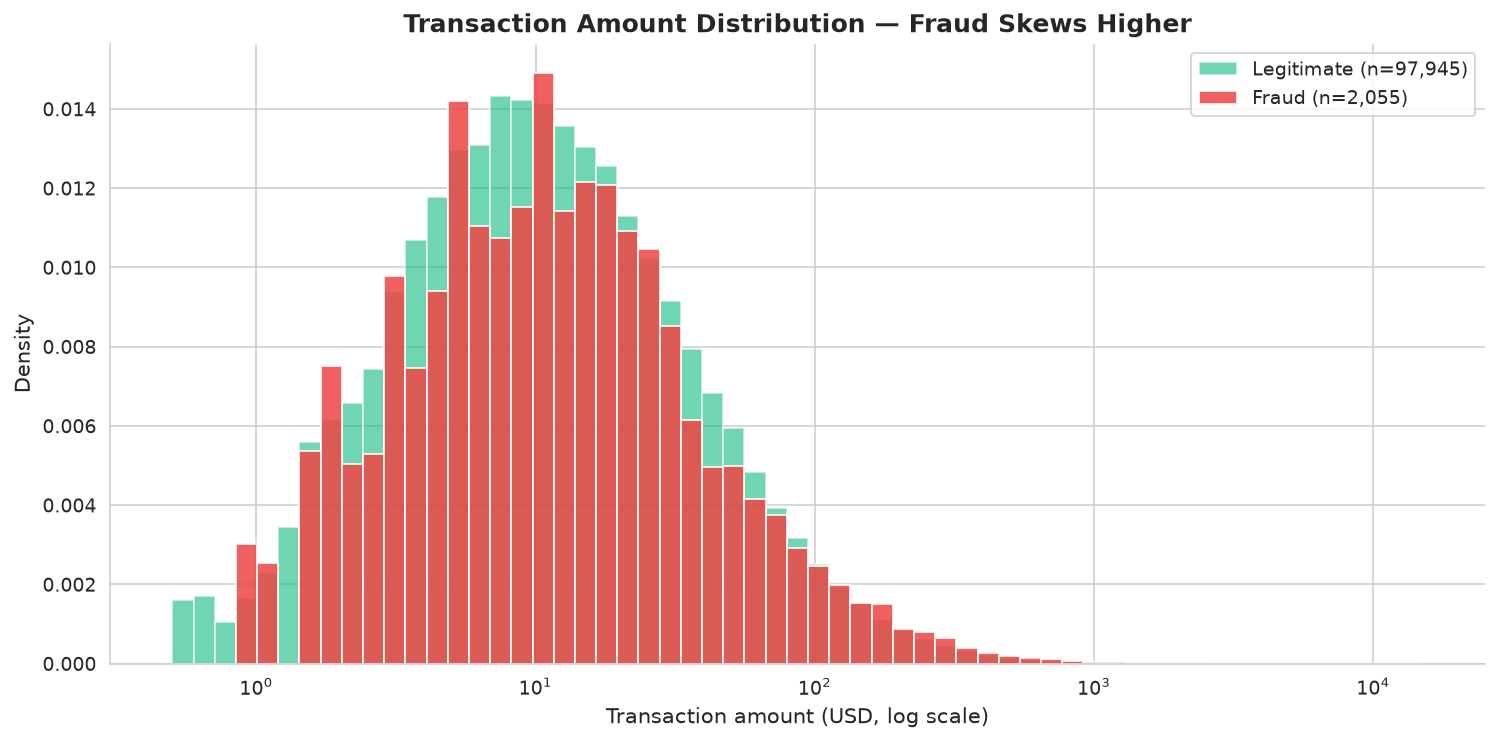

In [42]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.logspace(np.log10(0.5), np.log10(15000), 60)
ax.hist(df.loc[df["is_fraud"]==0, "transaction_amount"], bins=bins,
        color=PALETTE["success"], alpha=0.6, label=f"Legitimate (n={n_legit:,})", density=True)
ax.hist(df.loc[df["is_fraud"]==1, "transaction_amount"], bins=bins,
        color=PALETTE["danger"], alpha=0.85, label=f"Fraud (n={n_fraud:,})", density=True)
ax.set_xscale("log")
ax.set_title("Transaction Amount Distribution — Fraud Skews Higher", fontsize=13)
ax.set_xlabel("Transaction amount (USD, log scale)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/03_amount_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
print(f"Mean legit: ${headline_kpis['avg_legit_amount']}  |  Mean fraud: ${headline_kpis['avg_fraud_amount']}  (+{(headline_kpis['avg_fraud_amount']/headline_kpis['avg_legit_amount']-1)*100:.1f}%)")


Mean legit: $125.97  |  Mean fraud: $169.93  (+34.9%)


## 12. Chart 4 — Hourly Fraud Rate vs Volume

**What:** Dual-axis chart with transaction volume (bar, left axis) and fraud
rate % (line, right axis) by hour of day (0-23).

**Why:** The hour-of-day dimension carries one of the strongest fraud signals
in the dataset — the 00:00-05:00 window shows 7-11% fraud rates versus a 2%
baseline during business hours. Making this visible alongside volume (which is
lowest overnight) shows why per-segment fraud-rate lens beats raw fraud counts.

**How:** `groupby("transaction_hour")` aggregating size + mean(is_fraud),
matplotlib `twinx()` for the dual axis, bar+line combination, percent
formatter on the right axis.


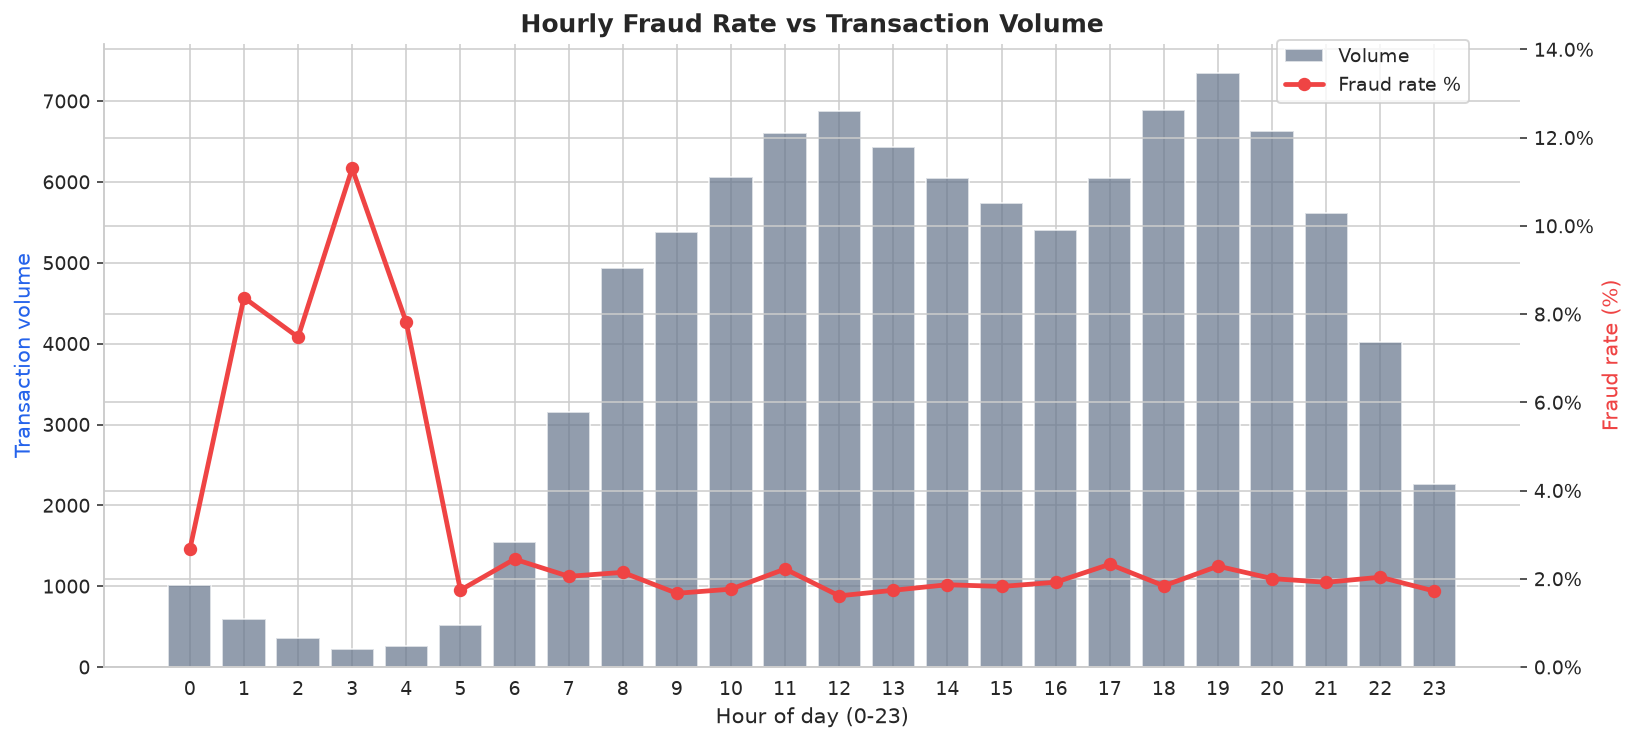

In [44]:
hour_stats = df.groupby("transaction_hour").agg(
    n=("is_fraud", "size"),
    frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.bar(hour_stats["transaction_hour"], hour_stats["n"],
        color=PALETTE["neutral"], alpha=0.7, label="Volume")
ax1.set_xlabel("Hour of day (0-23)")
ax1.set_ylabel("Transaction volume", color=PALETTE["primary"])
ax2 = ax1.twinx()
ax2.plot(hour_stats["transaction_hour"], hour_stats["fraud_rate"]*100,
         color=PALETTE["danger"], marker="o", linewidth=2.5, label="Fraud rate %")
ax2.set_ylabel("Fraud rate (%)", color=PALETTE["danger"])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, max(hour_stats["fraud_rate"]*100) * 1.25)
ax1.set_title("Hourly Fraud Rate vs Transaction Volume", fontsize=13)
ax1.set_xticks(range(0, 24))
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.95))
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/04_hourly_fraud_rate.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
peak_hr = hour_stats.loc[hour_stats["fraud_rate"].idxmax(), "transaction_hour"]
print(f"Peak fraud hour: {peak_hr:02d}:00  ({hour_stats['fraud_rate'].max()*100:.2f}% fraud rate)")

Peak fraud hour: 03:00  (11.30% fraud rate)


## 13. Chart 5 — Fraud Rate by Merchant Category

**What:** Horizontal bar chart of fraud rate (%) by each of the 15 merchant
categories, sorted descending, with absolute counts in the labels.

**Why:** Merchant category is one of the strongest segment-level signals —
fraud rate varies 2.5× from Online Retail (3.32%) down to Education (1.32%).
This view tells the rule-engine designer which categories deserve tighter
velocity thresholds and which can run light-touch rules.

**How:** `groupby("merchant_category")` with mean(is_fraud) and size,
sort descending, `barh()` with a colour ramp, label each bar with the rate
and the underlying sample size.


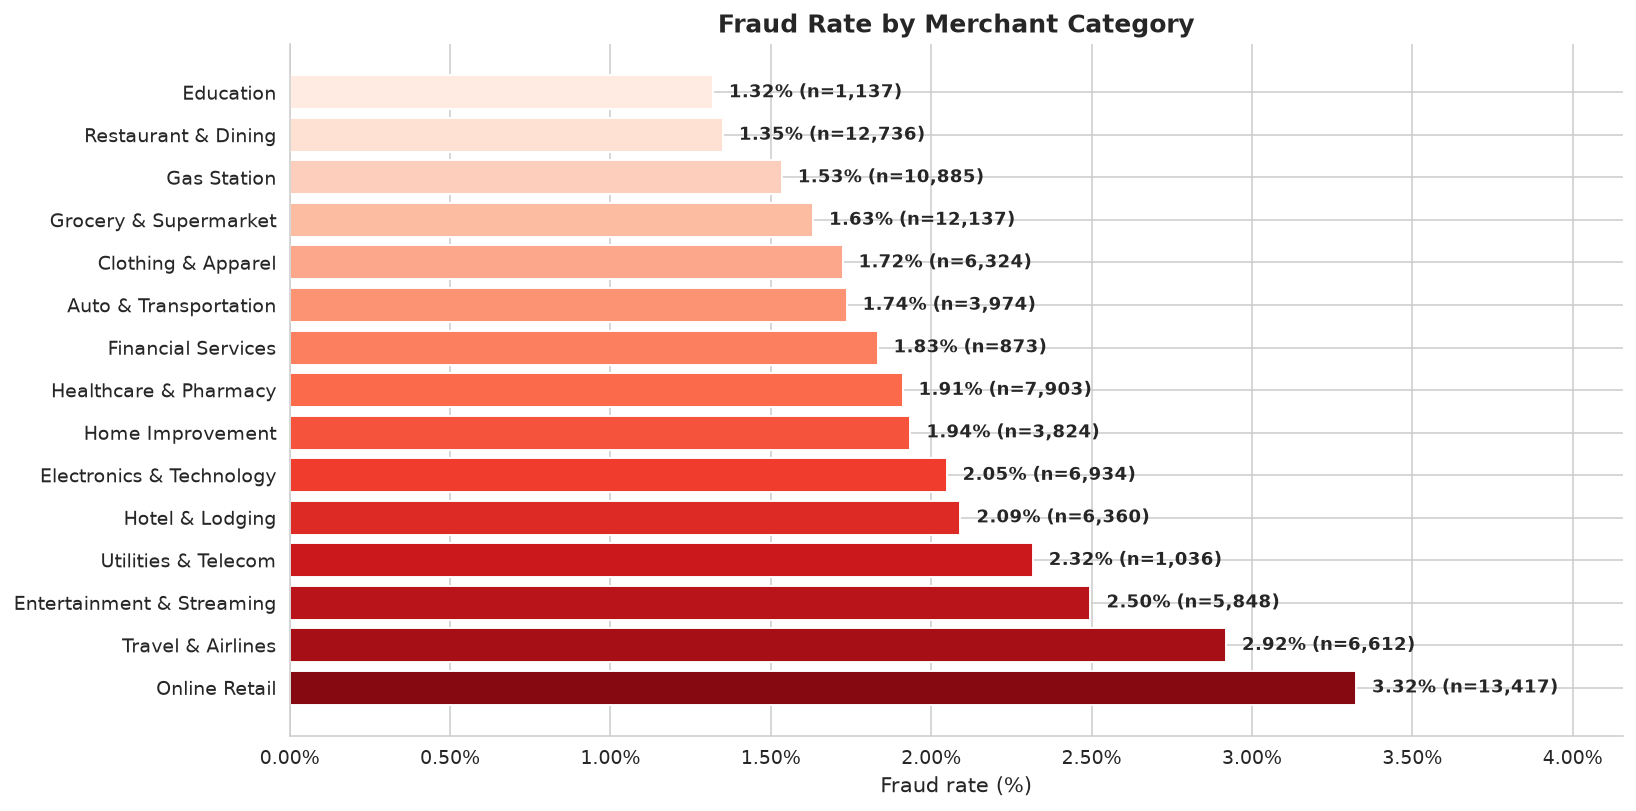

In [46]:
cat_stats = df.groupby("merchant_category").agg(
    n=("is_fraud", "size"),
    frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    fraud_loss=("fraud_amount_lost", "sum"),
).reset_index().sort_values("fraud_rate", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("Reds_r", len(cat_stats))
bars = ax.barh(cat_stats["merchant_category"], cat_stats["fraud_rate"]*100, color=colors)
for b, v, n in zip(bars, cat_stats["fraud_rate"]*100, cat_stats["n"]):
    ax.text(v + 0.05, b.get_y() + b.get_height()/2,
            f"{v:.2f}% (n={n:,})", va="center", fontsize=9.5, fontweight="bold")
ax.set_title("Fraud Rate by Merchant Category", fontsize=13)
ax.set_xlabel("Fraud rate (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, max(cat_stats["fraud_rate"]*100) * 1.25)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/05_fraud_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
print(f"Highest-risk category: {cat_stats.iloc[0]['merchant_category']} ({cat_stats.iloc[0]['fraud_rate']*100:.2f}%)")
print(f"Lowest-risk category : {cat_stats.iloc[-1]['merchant_category']} ({cat_stats.iloc[-1]['fraud_rate']*100:.2f}%)")


Highest-risk category: Online Retail (3.32%)
Lowest-risk category : Education (1.32%)


## 14. Chart 6 — Total Fraud Loss ($) by Merchant Category

**Why:** While the previous chart shows fraud *rate*, this chart shows fraud
*loss* — the dollar impact. Travel & Airlines has fewer fraud cases than
Online Retail but produces higher absolute loss because airline bookings carry
higher per-transaction amounts. This view is what the CFO needs to see when
prioritising mitigation spend.

**How:** Same `cat_stats` aggregation, but sort by `fraud_loss` descending and
plot `barh` of the loss column with $-formatted labels.


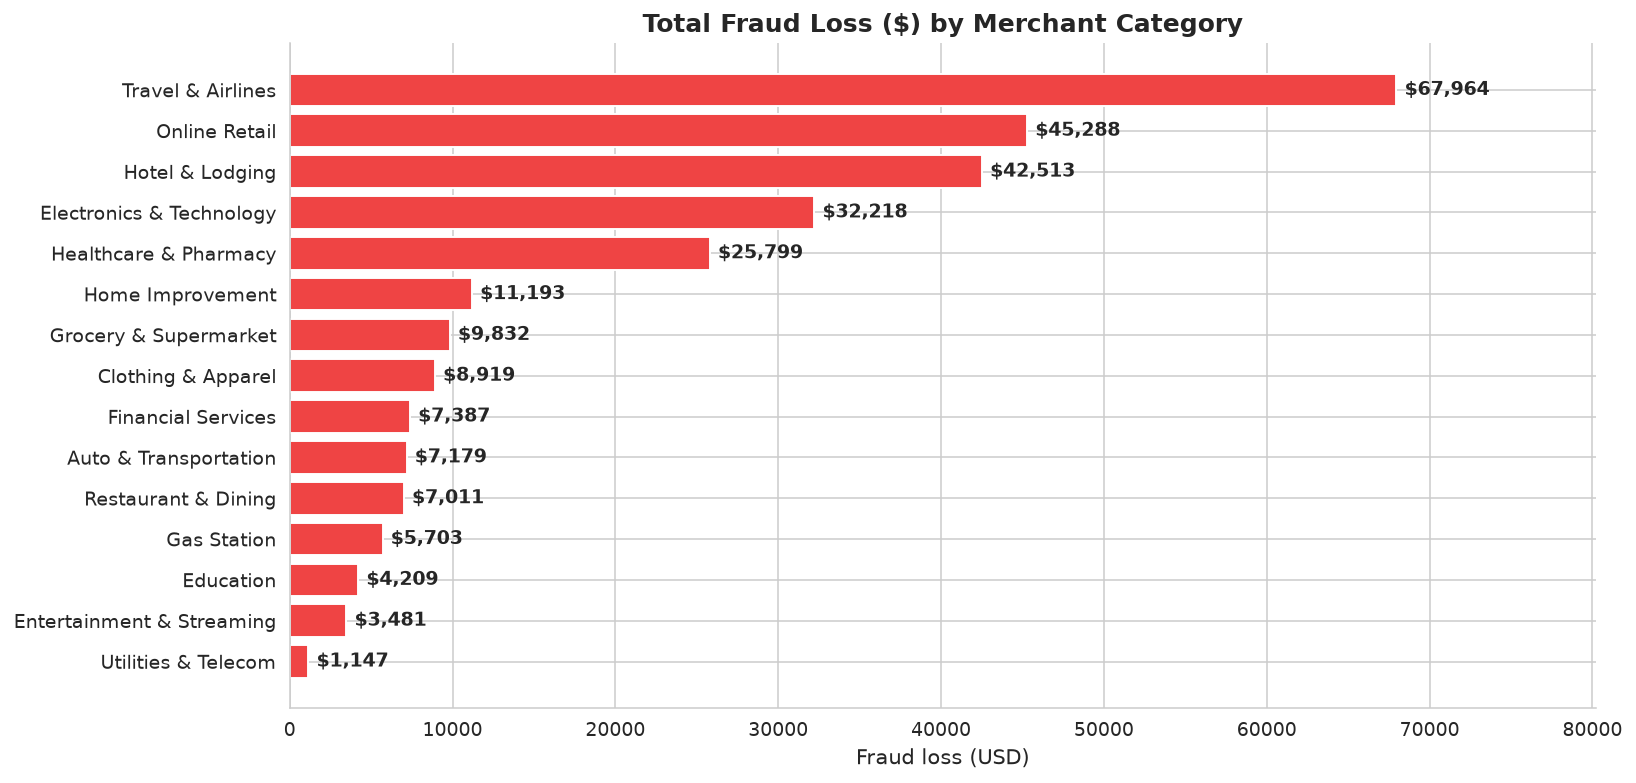

In [48]:
cat_loss = cat_stats.sort_values("fraud_loss", ascending=False)
fig, ax = plt.subplots(figsize=(12, 5.8))
bars = ax.barh(cat_loss["merchant_category"], cat_loss["fraud_loss"], color=PALETTE["danger"])
for b, v in zip(bars, cat_loss["fraud_loss"]):
    ax.text(v + 500, b.get_y() + b.get_height()/2,
            f"${v:,.0f}", va="center", fontsize=10, fontweight="bold")
ax.set_title("Total Fraud Loss ($) by Merchant Category", fontsize=13)
ax.set_xlabel("Fraud loss (USD)")
ax.invert_yaxis()
ax.set_xlim(0, max(cat_loss["fraud_loss"]) * 1.18)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/06_fraud_loss_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
print(f"Top loss category: {cat_loss.iloc[0]['merchant_category']} (${cat_loss.iloc[0]['fraud_loss']:,.0f})")

Top loss category: Travel & Airlines ($67,964)


## 15. Chart 7 — Fraud Rate by Channel and Device (side-by-side bars)

**What:** Two subplot bar charts: fraud rate by `transaction_channel` (4
values) and by `device_type` (4 values), each labelled with the fraud rate
and sample size.

**Why:** The Online channel (3.18% fraud rate) is 4× riskier than In-store
(0.80%) — the largest channel-level variance in the dataset. 
**How:** `groupby` on each column with `mean(is_fraud)` and `size`, two
matplotlib subplots with shared y-axis semantics, percent formatter.


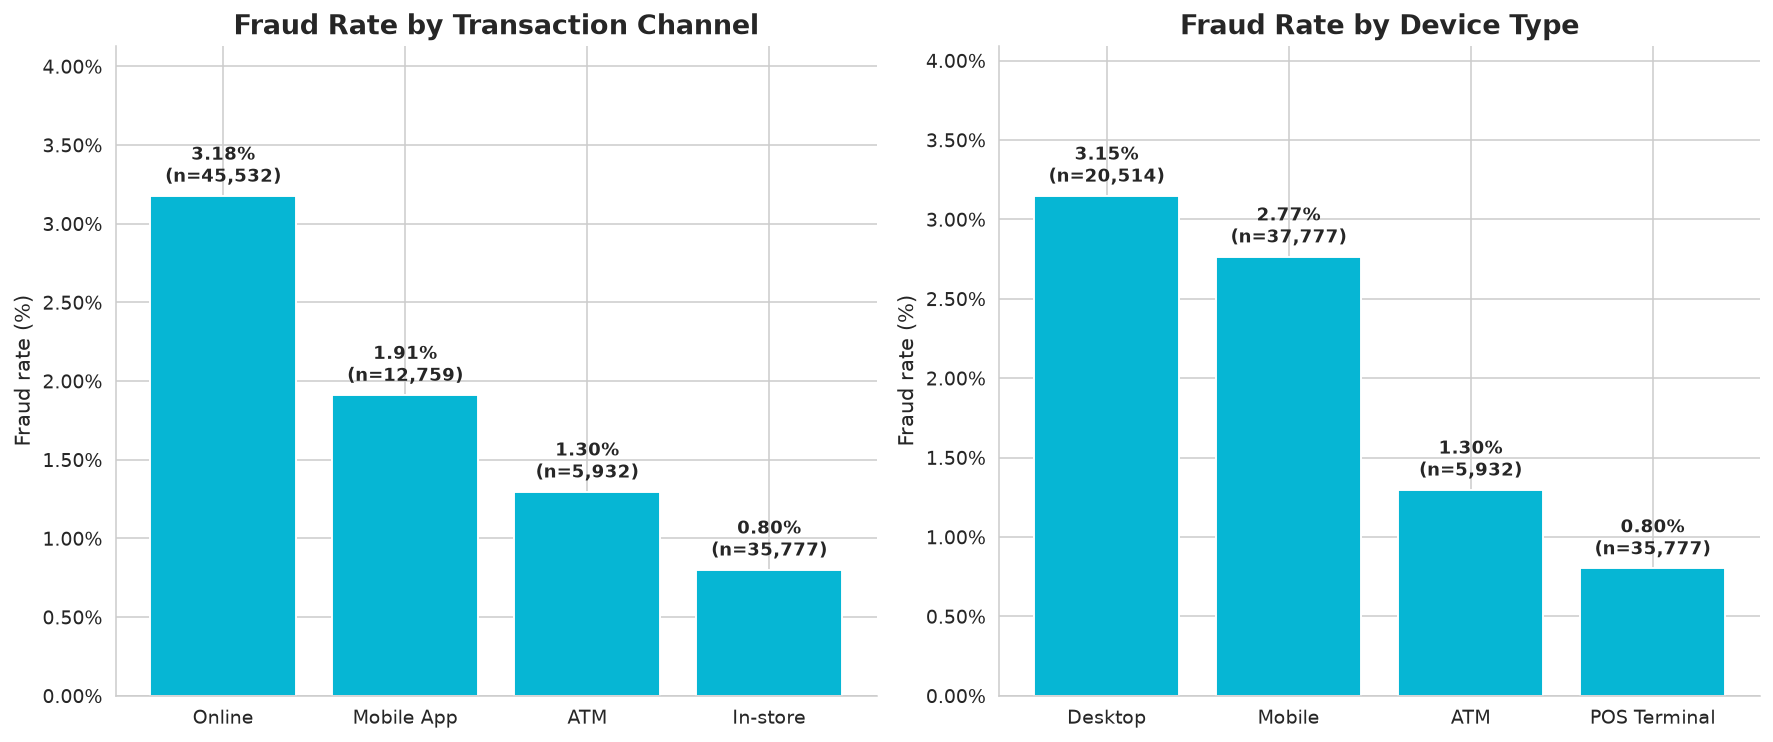

In [50]:
chan_stats = df.groupby("transaction_channel").agg(
    n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean"), frauds=("is_fraud", "sum")
).reset_index().sort_values("fraud_rate", ascending=False)
dev_stats = df.groupby("device_type").agg(
    n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean"), frauds=("is_fraud", "sum")
).reset_index().sort_values("fraud_rate", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, st, ttl in zip(axes, [chan_stats, dev_stats], ["Transaction Channel", "Device Type"]):
    bars = ax.bar(st.iloc[:, 0], st["fraud_rate"]*100, color=PALETTE["secondary"])
    for b, v, n in zip(bars, st["fraud_rate"]*100, st["n"]):
        ax.text(b.get_x() + b.get_width()/2, v + 0.05, f"{v:.2f}%\n(n={n:,})",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold")
    ax.set_title(f"Fraud Rate by {ttl}")
    ax.set_ylabel("Fraud rate (%)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylim(0, max(st["fraud_rate"]*100) * 1.3)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/07_fraud_by_channel_device.png", dpi=150, bbox_inches="tight")
plt.show()

In [51]:
print(f"Online fraud rate  : {chan_stats[chan_stats['transaction_channel']=='Online']['fraud_rate'].iloc[0]*100:.2f}%")
print(f"In-store fraud rate: {chan_stats[chan_stats['transaction_channel']=='In-store']['fraud_rate'].iloc[0]*100:.2f}%")

Online fraud rate  : 3.18%
In-store fraud rate: 0.80%


## 16. Chart 8 — Fraud Rate by Merchant Country

**What:** Bar chart of fraud rate (%) by each of the 20 merchant countries,
sorted descending, colour-graded red→yellow→green by risk tier.

**Why:** The four high-risk countries (Romania, Russia, Nigeria, China) carry
9.87%–12.94% fraud rates versus a 1.94% baseline — a 5-7× multiplier. This
is the widest segment-level spread in the entire dataset and is the
justification for country-tiered rule severity.

**How:** `groupby("merchant_country")` with mean(is_fraud), sort descending,
matplotlib bar with `sns.color_palette("RdYlGn_r", 20)` for a traffic-light
gradient. Rotate country labels for readability.


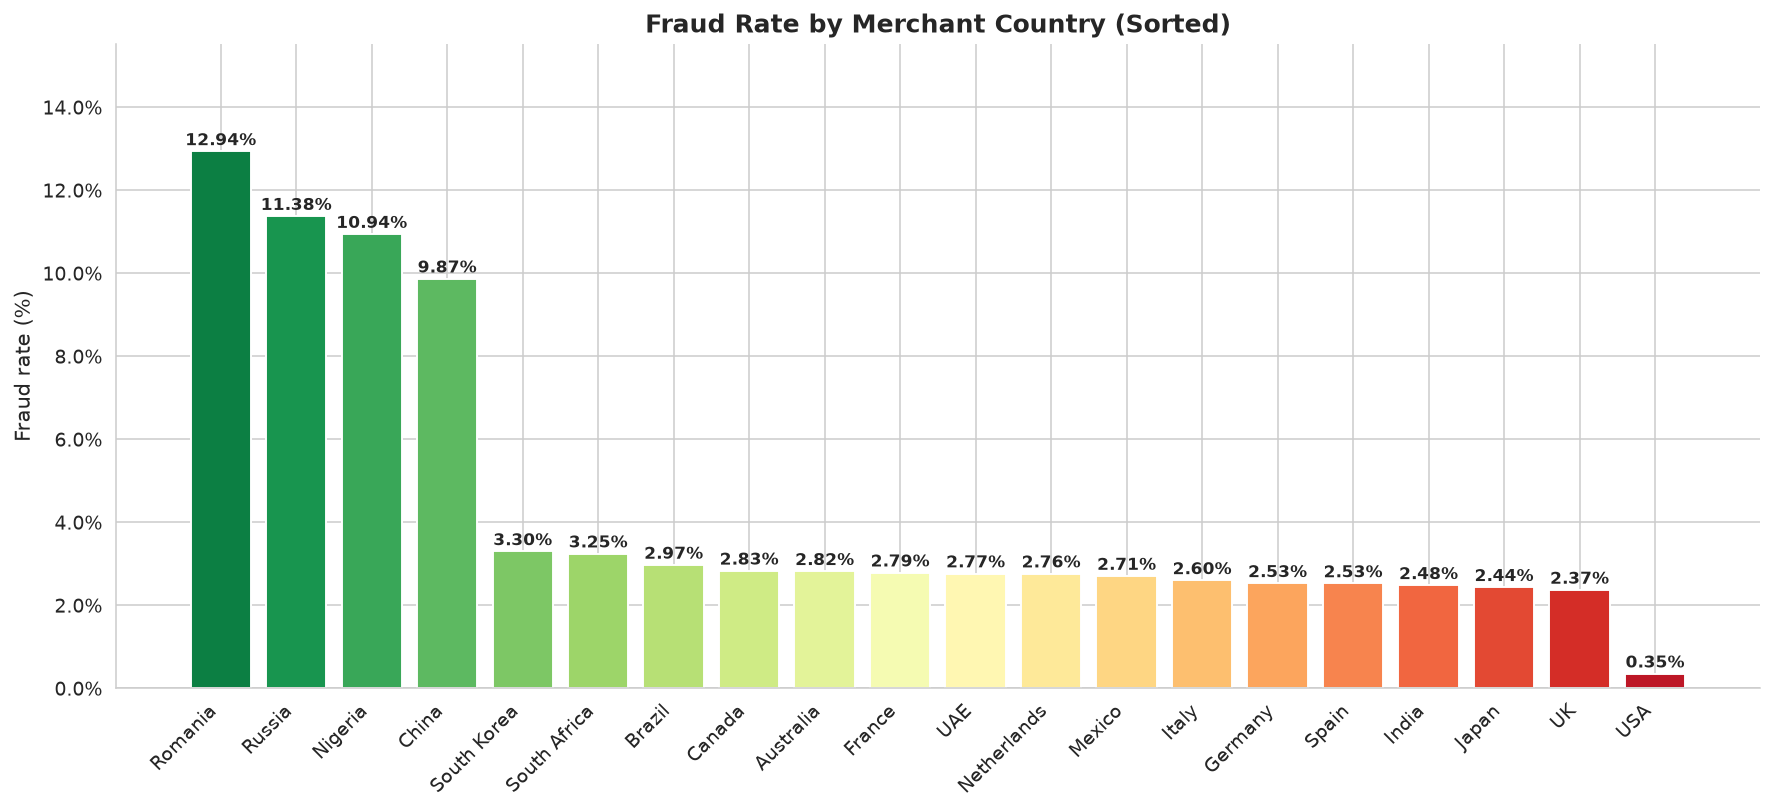

In [52]:
country_stats = df.groupby("merchant_country").agg(
    n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean"), frauds=("is_fraud", "sum")
).reset_index().sort_values("fraud_rate", ascending=False)

fig, ax = plt.subplots(figsize=(13, 6))
palette = sns.color_palette("RdYlGn_r", len(country_stats))
bars = ax.bar(country_stats["merchant_country"], country_stats["fraud_rate"]*100, color=palette)
for b, v, n in zip(bars, country_stats["fraud_rate"]*100, country_stats["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.05, f"{v:.2f}%",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_title("Fraud Rate by Merchant Country (Sorted)", fontsize=13)
ax.set_ylabel("Fraud rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticklabels(country_stats["merchant_country"], rotation=45, ha="right")
ax.set_ylim(0, max(country_stats["fraud_rate"]*100) * 1.2)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/08_fraud_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
print(f"Highest-risk country: {country_stats.iloc[0]['merchant_country']} ({country_stats.iloc[0]['fraud_rate']*100:.2f}%)")
print(f"Lowest-risk country : {country_stats.iloc[-1]['merchant_country']} ({country_stats.iloc[-1]['fraud_rate']*100:.2f}%)")


Highest-risk country: Romania (12.94%)
Lowest-risk country : USA (0.35%)


## 17. Chart 9 — Monthly Fraud Trend (Volume vs Rate)

**What:** Dual-axis time-series chart of monthly transaction volume (bar) and
fraud rate % (line) across the 12 months of 2026.

**Why:** October peaks at 2.29% and June troughs at 1.87%. The peak-to-trough
spread of 0.42 percentage points (~22% relative variation) is meaningful
enough to justify seasonal rule-tuning — Q4 should run slightly tighter
velocity thresholds than Q2.

**How:** `groupby(df["transaction_datetime"].dt.month)` aggregating size and
mean(is_fraud), map month numbers to short names, `twinx()` for the dual axis.


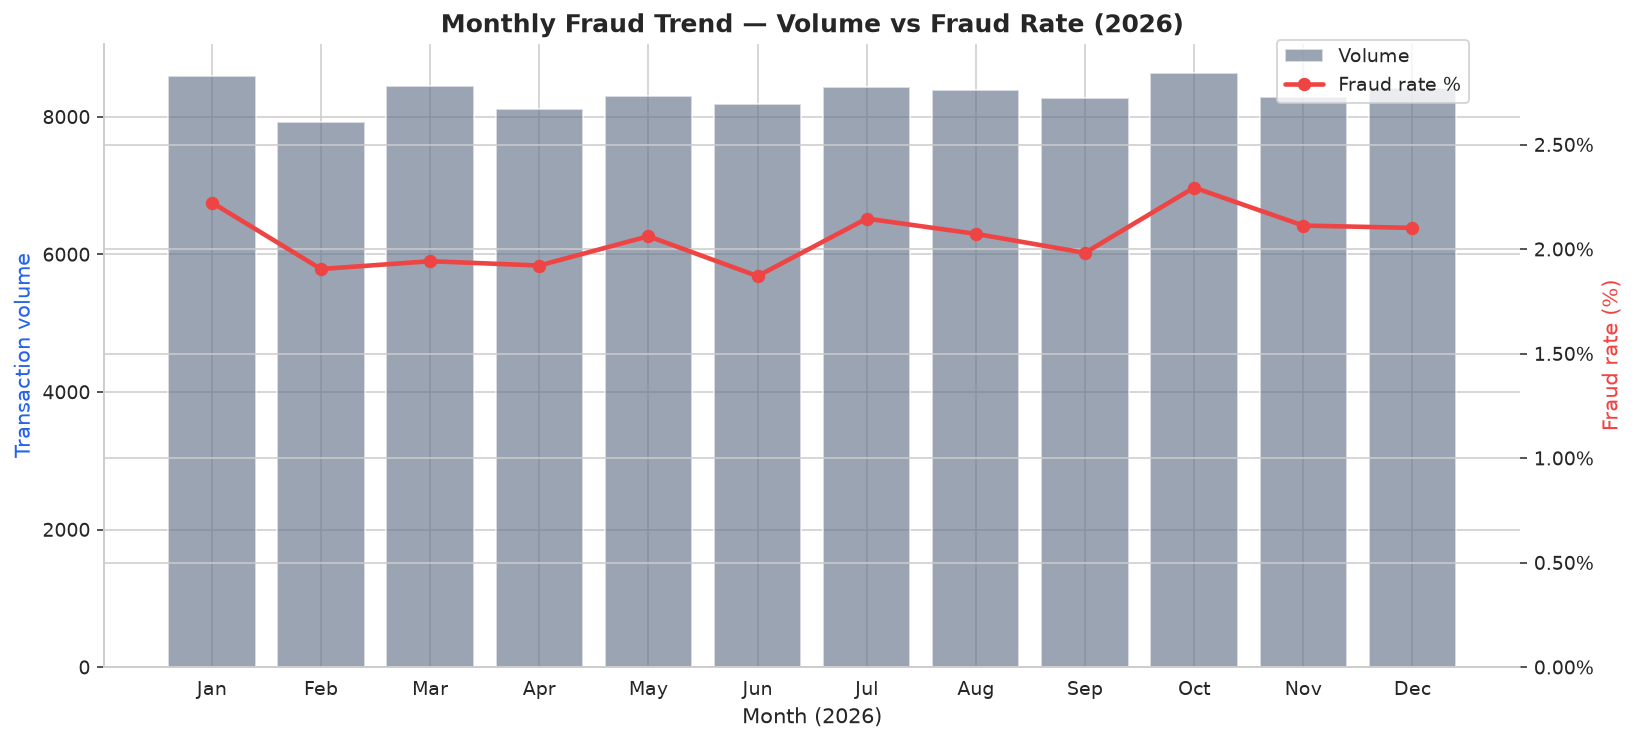

In [54]:
month_stats = df.groupby("txn_month").agg(
    n=("is_fraud", "size"), frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"), fraud_loss=("fraud_amount_lost", "sum")
).reset_index()
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
month_stats["label"] = month_stats["txn_month"].apply(lambda m: month_names[m-1])

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.bar(month_stats["label"], month_stats["n"], color=PALETTE["neutral"], alpha=0.65, label="Volume")
ax1.set_ylabel("Transaction volume", color=PALETTE["primary"])
ax1.set_xlabel("Month (2026)")
ax2 = ax1.twinx()
ax2.plot(month_stats["label"], month_stats["fraud_rate"]*100,
         color=PALETTE["danger"], marker="o", linewidth=2.4, label="Fraud rate %")
ax2.set_ylabel("Fraud rate (%)", color=PALETTE["danger"])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
ax2.set_ylim(0, max(month_stats["fraud_rate"]*100) * 1.3)
ax1.set_title("Monthly Fraud Trend — Volume vs Fraud Rate (2026)", fontsize=13)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.95))
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/09_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [55]:
peak_m = month_stats.loc[month_stats["fraud_rate"].idxmax()]
trough_m = month_stats.loc[month_stats["fraud_rate"].idxmin()]
print(f"Peak month:   {peak_m['label']} ({peak_m['fraud_rate']*100:.2f}%)")
print(f"Trough month: {trough_m['label']} ({trough_m['fraud_rate']*100:.2f}%)")


Peak month:   Oct (2.29%)
Trough month: Jun (1.87%)


## 18. Chart 10 — Fraud Rate by Day of Week (Weekend vs Weekday)

**What:** Bar chart of fraud rate by each of the 7 days of week, with weekend
days (Saturday/Sunday) coloured red and weekdays blue.

**Why:** An important null finding — unlike hour-of-day, the calendar-day
dimension carries no useful signal. Weekend (2.09%) vs weekday (2.04%) fraud
rate difference is < 0.05 percentage points. This justifies a 24×7 staffing
model rather than a 5×9 model with weekend premium.

**How:** `groupby("transaction_day_of_week")`, reindex to Mon→Sun order,
conditional colour assignment based on day name in weekend set, percent labels.


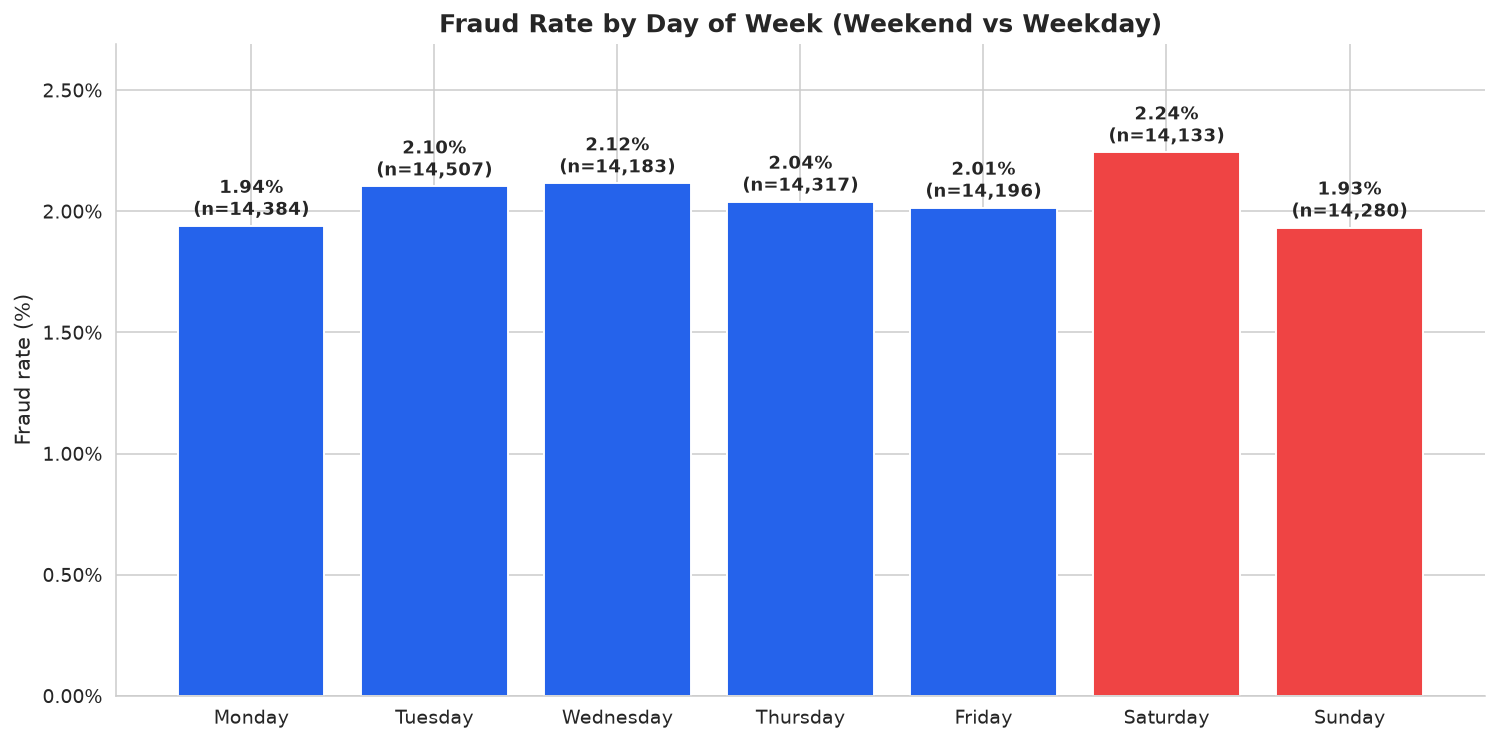

In [56]:
dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow_stats = df.groupby("transaction_day_of_week").agg(
    n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean"), frauds=("is_fraud", "sum")
).reindex(dow_order).reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(dow_stats["transaction_day_of_week"], dow_stats["fraud_rate"]*100,
              color=[PALETTE["primary"] if d in dow_order[:5] else PALETTE["danger"]
                     for d in dow_stats["transaction_day_of_week"]])
for b, v, n in zip(bars, dow_stats["fraud_rate"]*100, dow_stats["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.2f}%\n(n={n:,})",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_title("Fraud Rate by Day of Week (Weekend vs Weekday)", fontsize=13)
ax.set_ylabel("Fraud rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, max(dow_stats["fraud_rate"]*100) * 1.2)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/10_dow_fraud_rate.png", dpi=150, bbox_inches="tight")
plt.show()

In [57]:
print(f"Weekend fraud rate: {df[df['is_weekend']==1]['is_fraud'].mean()*100:.3f}%")
print(f"Weekday fraud rate: {df[df['is_weekend']==0]['is_fraud'].mean()*100:.3f}%")


Weekend fraud rate: 2.087%
Weekday fraud rate: 2.042%


## 19. Chart 11 — Pearson Correlation Heatmap (Numeric Features vs is_fraud)

**What:** Lower-triangular Pearson correlation heatmap of every numeric
feature against every other, with the target `is_fraud` highlighted via the
rightmost column.

**Why:** The correlation scan surfaces the rank-ordered driver list. The
strongest non-outcome correlation is `high_risk_country` (r=0.144), followed
by `international_transaction` (r=0.107) and `distance_from_home_km` (r=0.081).
This is the evidence base for the rule-engine feature selection.

**How:** `df.select_dtypes(include=[np.number])` to get numeric columns,
exclude `is_fraud` itself from the source list but include it as the target
column, `df.corr()`, `sns.heatmap()` with `mask=np.triu(...)` for the lower
triangle.


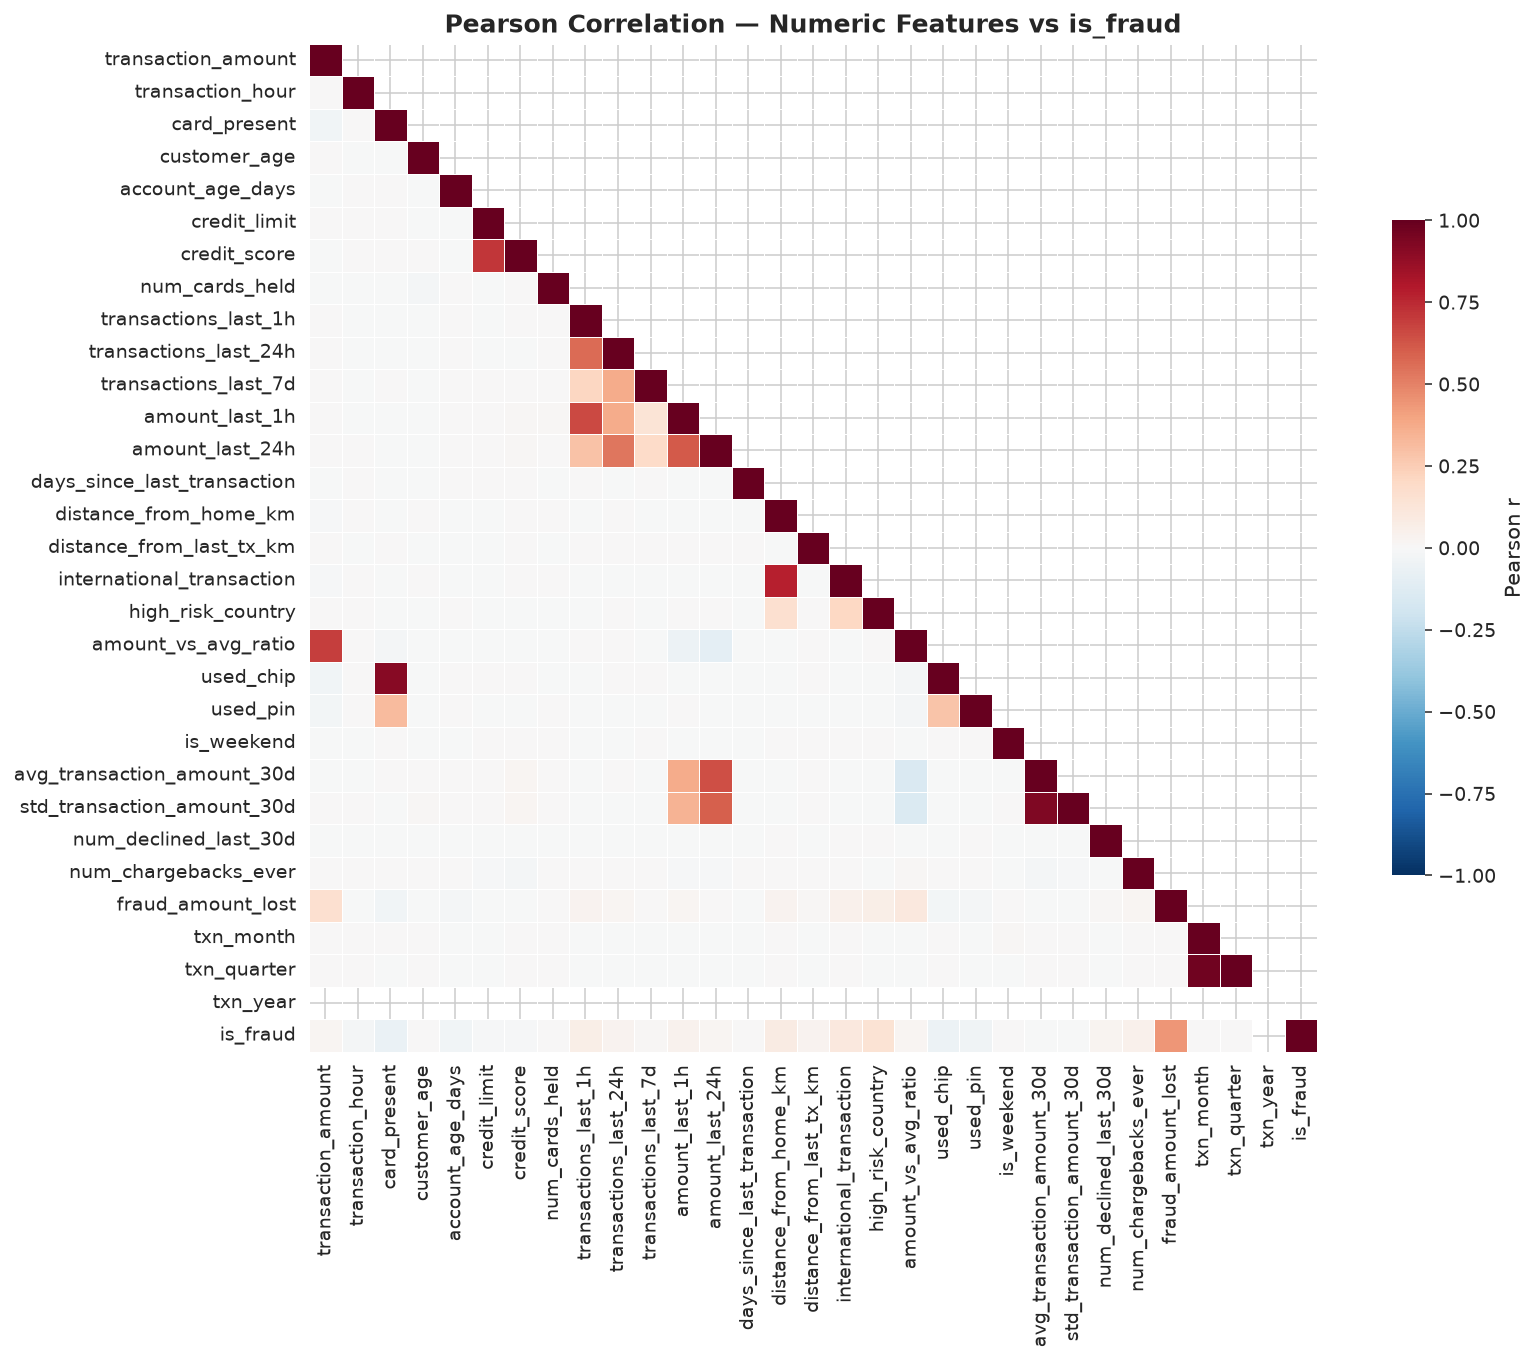

In [58]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ("is_fraud",)]
corr = df[num_cols + ["is_fraud"]].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.65, "label": "Pearson r"},
            annot=False, ax=ax)
ax.set_title("Pearson Correlation — Numeric Features vs is_fraud", fontsize=13)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/11_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [59]:
top_corr = corr["is_fraud"].drop("is_fraud").sort_values(ascending=False).head(10)
for f, r in top_corr.items():
    print(f"   {f:<30} r={r:+.4f}")

   fraud_amount_lost              r=+0.4424
   high_risk_country              r=+0.1444
   international_transaction      r=+0.1075
   distance_from_home_km          r=+0.0806
   transactions_last_1h           r=+0.0645
   num_chargebacks_ever           r=+0.0499
   amount_last_1h                 r=+0.0429
   transactions_last_24h          r=+0.0341
   distance_from_last_tx_km       r=+0.0314
   num_declined_last_30d          r=+0.0284


## 20. Chart 12 — Fraud Rate by Binary Risk Flag (0 vs 1)

**What:** Bar chart comparing fraud rate when each binary risk flag is 0 vs 1,
for all six flags: international_transaction, high_risk_country, used_chip,
used_pin, card_present, is_weekend.

**Why:** This view quantifies the fraud-rate multiplier of each flag.
`high_risk_country=1` shows 11.05% fraud rate vs 1.94% for =0 — a 5.7×
multiplier. `international_transaction=1` shows 3.42% vs 0.35% — a 10×
multiplier. These multipliers are the foundation of the tiered rule design.

**How:** Loop over each binary flag, build a small DataFrame of flag-value
pairs with `n` and `fraud_rate`, plot as a single bar chart with conditional
colours (0=light, 1=red).


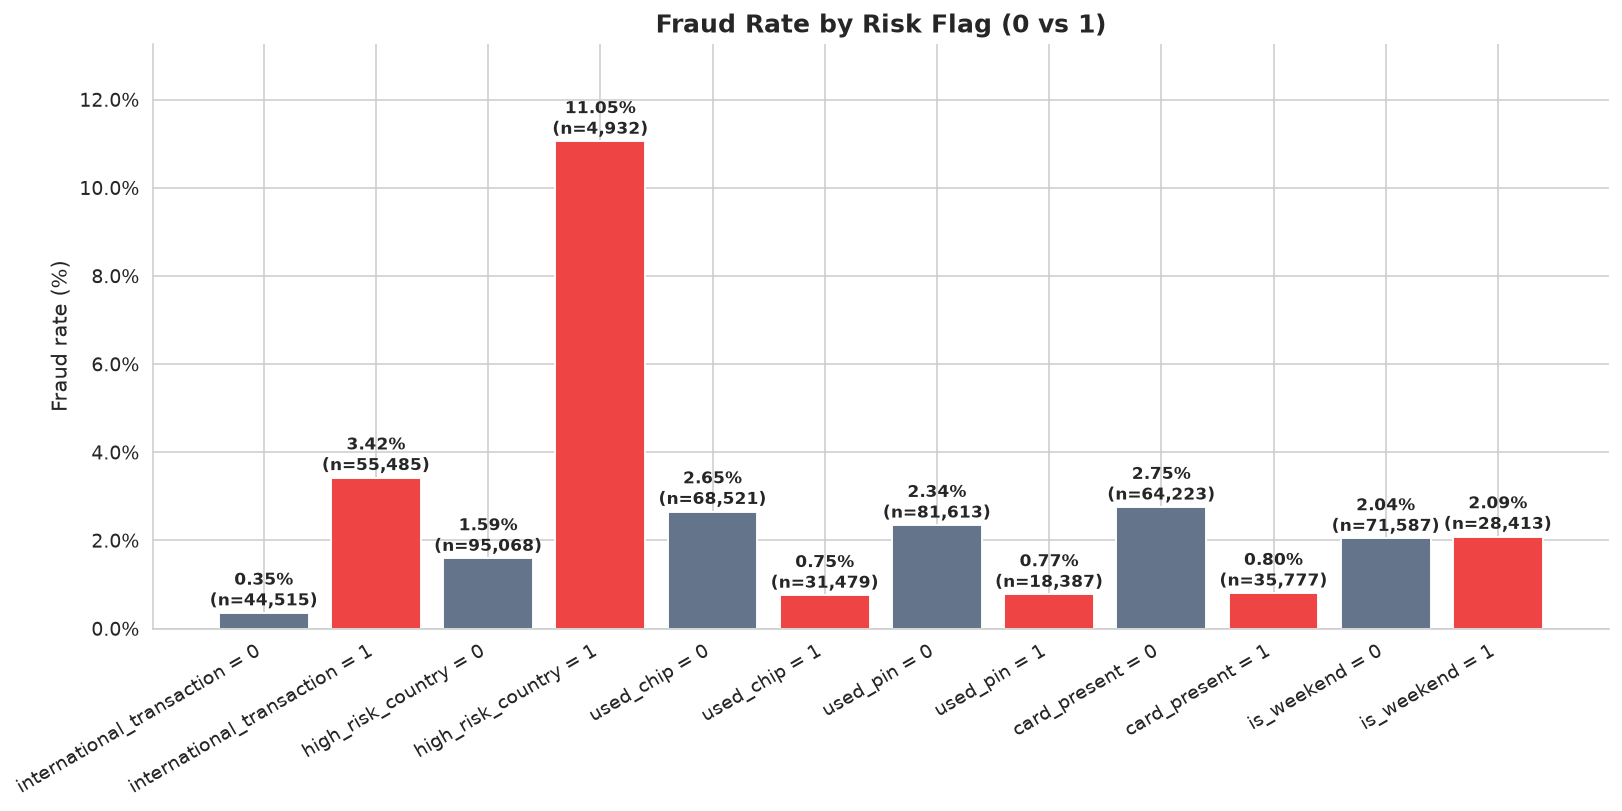

In [60]:
binary_flags = ["international_transaction","high_risk_country","used_chip",
                "used_pin","card_present","is_weekend"]
flag_stats = []
for f in binary_flags:
    for v in [0, 1]:
        sub = df[df[f] == v]
        flag_stats.append({"flag": f, "value": v, "n": len(sub),
                           "frauds": int(sub["is_fraud"].sum()),
                           "fraud_rate": float(sub["is_fraud"].mean()) if len(sub) else 0})
fs = pd.DataFrame(flag_stats)
fs["label"] = fs["flag"] + " = " + fs["value"].astype(str)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(fs["label"], fs["fraud_rate"]*100,
              color=[PALETTE["neutral"] if v == 0 else PALETTE["danger"] for v in fs["value"]])
for b, v, n in zip(bars, fs["fraud_rate"]*100, fs["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.04, f"{v:.2f}%\n(n={n:,})",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_title("Fraud Rate by Risk Flag (0 vs 1)", fontsize=13)
ax.set_ylabel("Fraud rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticklabels(fs["label"], rotation=30, ha="right")
ax.set_ylim(0, max(fs["fraud_rate"]*100) * 1.2)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/12_fraud_by_flags.png", dpi=150, bbox_inches="tight")
plt.show()

In [61]:
hrc = df[df["high_risk_country"]==1]
intl = df[df["international_transaction"]==1]
print(f"high_risk_country=1   fraud rate: {hrc['is_fraud'].mean()*100:.2f}% (n={len(hrc):,})")
print(f"international_transaction=1 fraud rate: {intl['is_fraud'].mean()*100:.2f}% (n={len(intl):,})")


high_risk_country=1   fraud rate: 11.05% (n=4,932)
international_transaction=1 fraud rate: 3.42% (n=55,485)


## 21. Chart 13 — Average Transaction Amount: Legitimate vs Fraud by Category

**What:** Side-by-side bar chart of average transaction amount for legitimate
and fraud classes, broken down by each merchant category.

**Why:** Confirms the fraud-amount premium is not uniform across categories.
Travel & Airlines, Electronics, and Online Retail show the largest
fraud-vs-legitimate amount gap. Category-aware velocity rules should use a
tighter threshold for low-ticket categories (where $500 is anomalous) and a
looser threshold for high-ticket categories (where $500 is routine).

**How:** `groupby(["merchant_category", "is_fraud"])["transaction_amount"].mean()`,
`unstack()`, plot as grouped bars with `np.arange()` offsets.


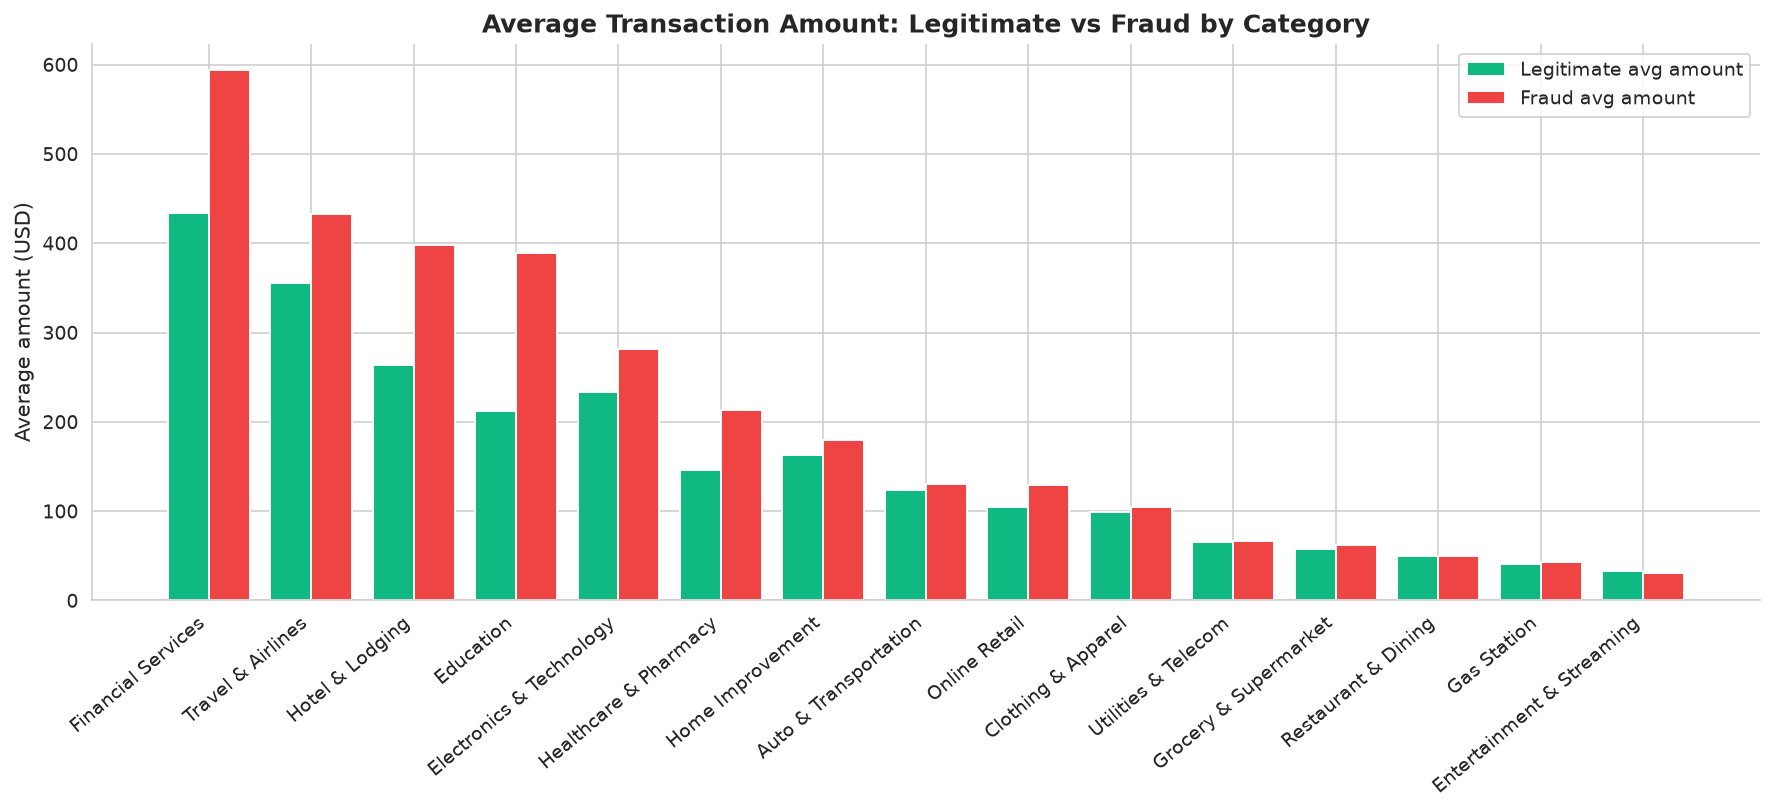

In [62]:
amt_by_cat = df.groupby(["merchant_category","is_fraud"])["transaction_amount"].mean().unstack()
amt_by_cat.columns = ["Legitimate_avg", "Fraud_avg"]
amt_by_cat = amt_by_cat.sort_values("Fraud_avg", ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(amt_by_cat))
w = 0.4
ax.bar(x - w/2, amt_by_cat["Legitimate_avg"], w, color=PALETTE["success"], label="Legitimate avg amount")
ax.bar(x + w/2, amt_by_cat["Fraud_avg"], w, color=PALETTE["danger"], label="Fraud avg amount")
ax.set_xticks(x)
ax.set_xticklabels(amt_by_cat["merchant_category"], rotation=40, ha="right")
ax.set_title("Average Transaction Amount: Legitimate vs Fraud by Category", fontsize=13)
ax.set_ylabel("Average amount (USD)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/13_avg_amount_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

## 23. Chart 15 — Top 15 Countries: Volume vs Fraud Rate

**What:** Dual-axis chart of transaction volume (bar) and fraud rate % (line)
for the top 15 countries by transaction volume.

**Why:** Volume and fraud rate are inversely correlated in this dataset —
high-volume countries (USA, UK, Canada) tend to have baseline fraud rates,
while lower-volume countries (Romania, Russia) often carry higher fraud rates.
Showing both on one chart makes this inverse relationship visible.

**How:** Sort `country_stats` by `n` descending, take top 15, `twinx()` for
dual axis with bar+line.


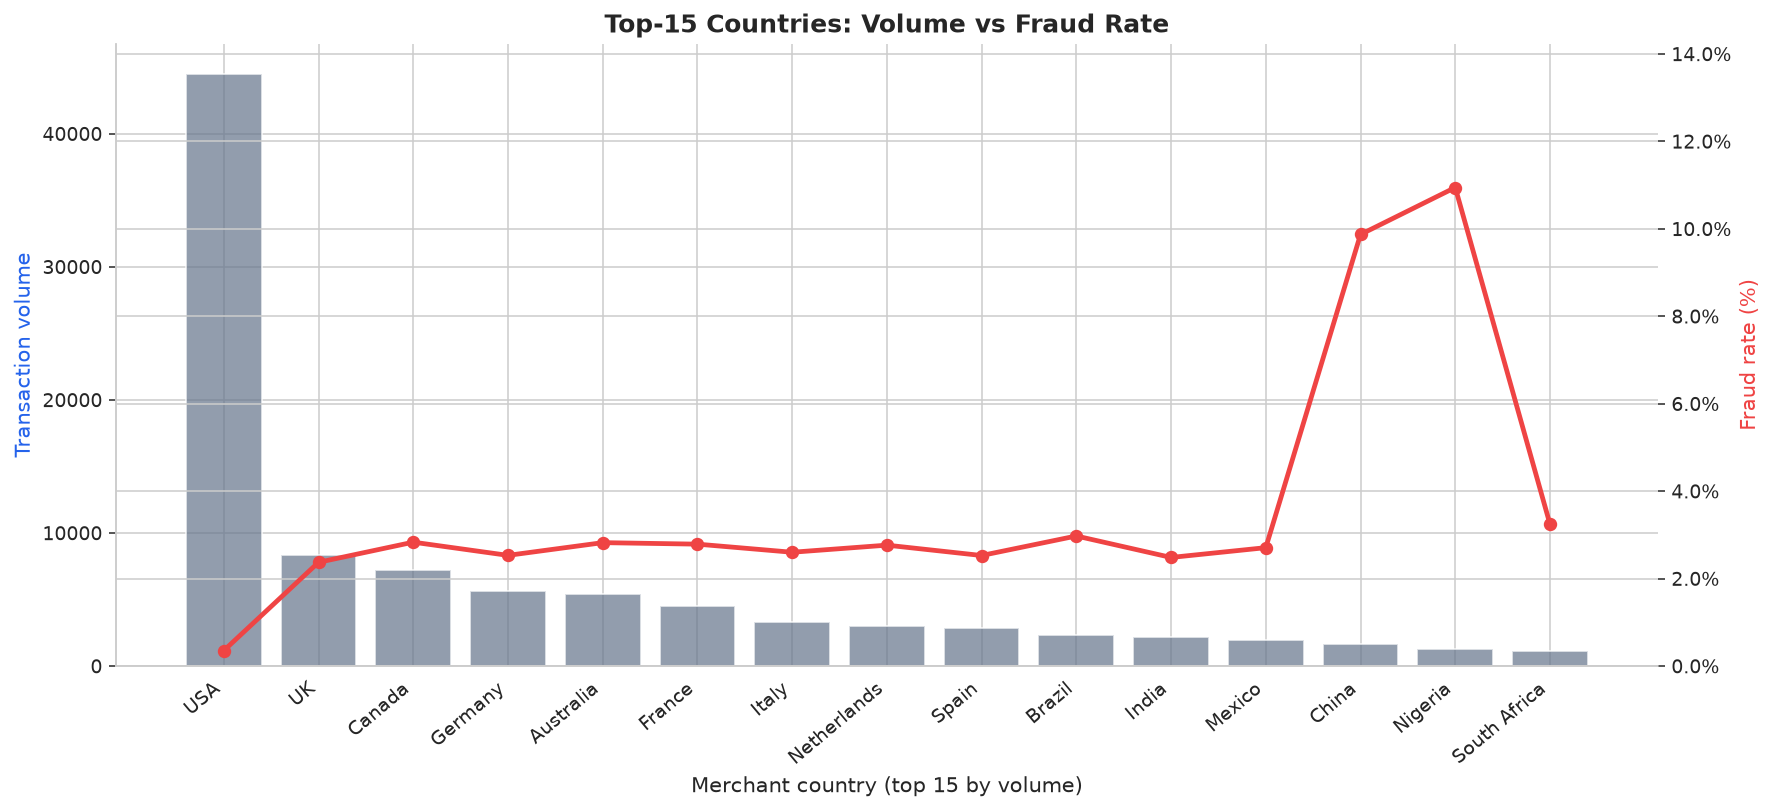

In [63]:
top15 = country_stats.sort_values("n", ascending=False).head(15)
fig, ax1 = plt.subplots(figsize=(13, 6))
ax1.bar(top15["merchant_country"], top15["n"], color=PALETTE["neutral"], alpha=0.7)
ax1.set_ylabel("Transaction volume", color=PALETTE["primary"])
ax1.set_xlabel("Merchant country (top 15 by volume)")
ax2 = ax1.twinx()
ax2.plot(top15["merchant_country"], top15["fraud_rate"]*100,
         color=PALETTE["danger"], marker="o", linewidth=2.5, label="Fraud rate %")
ax2.set_ylabel("Fraud rate (%)", color=PALETTE["danger"])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, max(top15["fraud_rate"]*100) * 1.3)
ax1.set_xticklabels(top15["merchant_country"], rotation=40, ha="right")
ax1.set_title("Top-15 Countries: Volume vs Fraud Rate", fontsize=13)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/15_top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

## 24. Chart 16 — Distance From Home Distribution (Fraud vs Legitimate)

**What:** Overlaid histograms of `distance_from_home_km` for fraud vs
legitimate classes, clipped at 15,000 km for chart readability.

**Why:** Fraud transactions skew toward higher distances — the upper tail of
the fraud distribution extends further than the legitimate distribution,
supporting the use of distance-based rules (e.g., flag any transaction >1,000
km from home combined with another elevated signal).

**How:** `np.clip()` on distance column to 15,000, `ax.hist()` twice with
`density=True`, transparency overlay.


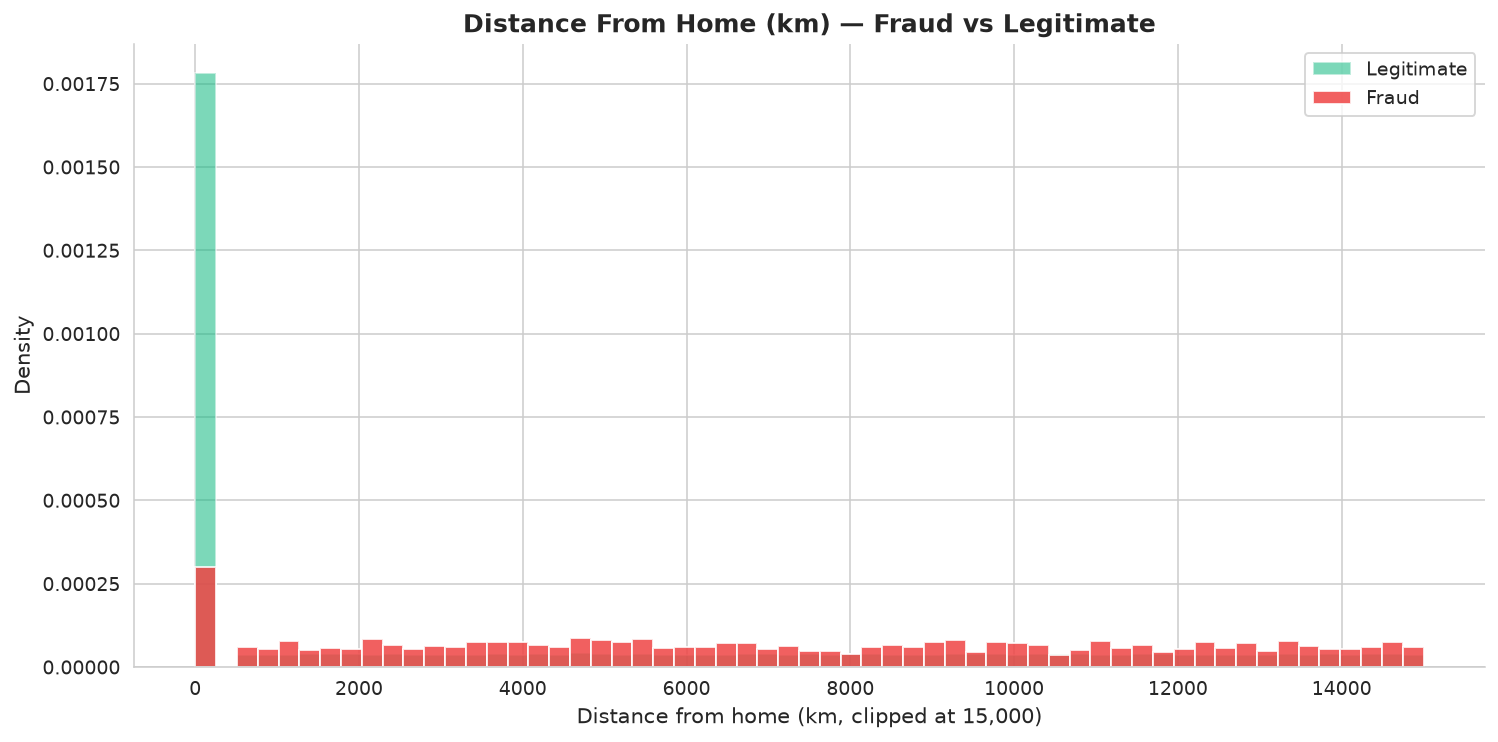

In [64]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.linspace(0, 15000, 60)
ax.hist(np.clip(df.loc[df["is_fraud"]==0, "distance_from_home_km"], 0, 15000),
        bins=bins, color=PALETTE["success"], alpha=0.55, label="Legitimate", density=True)
ax.hist(np.clip(df.loc[df["is_fraud"]==1, "distance_from_home_km"], 0, 15000),
        bins=bins, color=PALETTE["danger"], alpha=0.85, label="Fraud", density=True)
ax.set_title("Distance From Home (km) — Fraud vs Legitimate", fontsize=13)
ax.set_xlabel("Distance from home (km, clipped at 15,000)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/16_distance_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [65]:
print(f"Mean distance (legit): {df.loc[df['is_fraud']==0,'distance_from_home_km'].mean():.0f} km")
print(f"Mean distance (fraud): {df.loc[df['is_fraud']==1,'distance_from_home_km'].mean():.0f} km")


Mean distance (legit): 4259 km
Mean distance (fraud): 7070 km


## 25. Chart 17 — Credit Score & Customer Age by Fraud Status (violin)

**What:** Side-by-side violin plots of `credit_score` and `customer_age` for
fraud vs legitimate classes, on a 15K-row sub-sample for performance.

**Why:** Both demographic features show only modest fraud-rate signal — the
interquartile ranges overlap substantially, suggesting these are weak
standalone predictors but useful as covariates. The takeaway: do not anchor
rule logic on demographics, but include them in any multivariate model.

**How:** `df.sample(15000)` for performance, `sns.violinplot()` with
`inner="quartile"` to show IQR inside the violin.


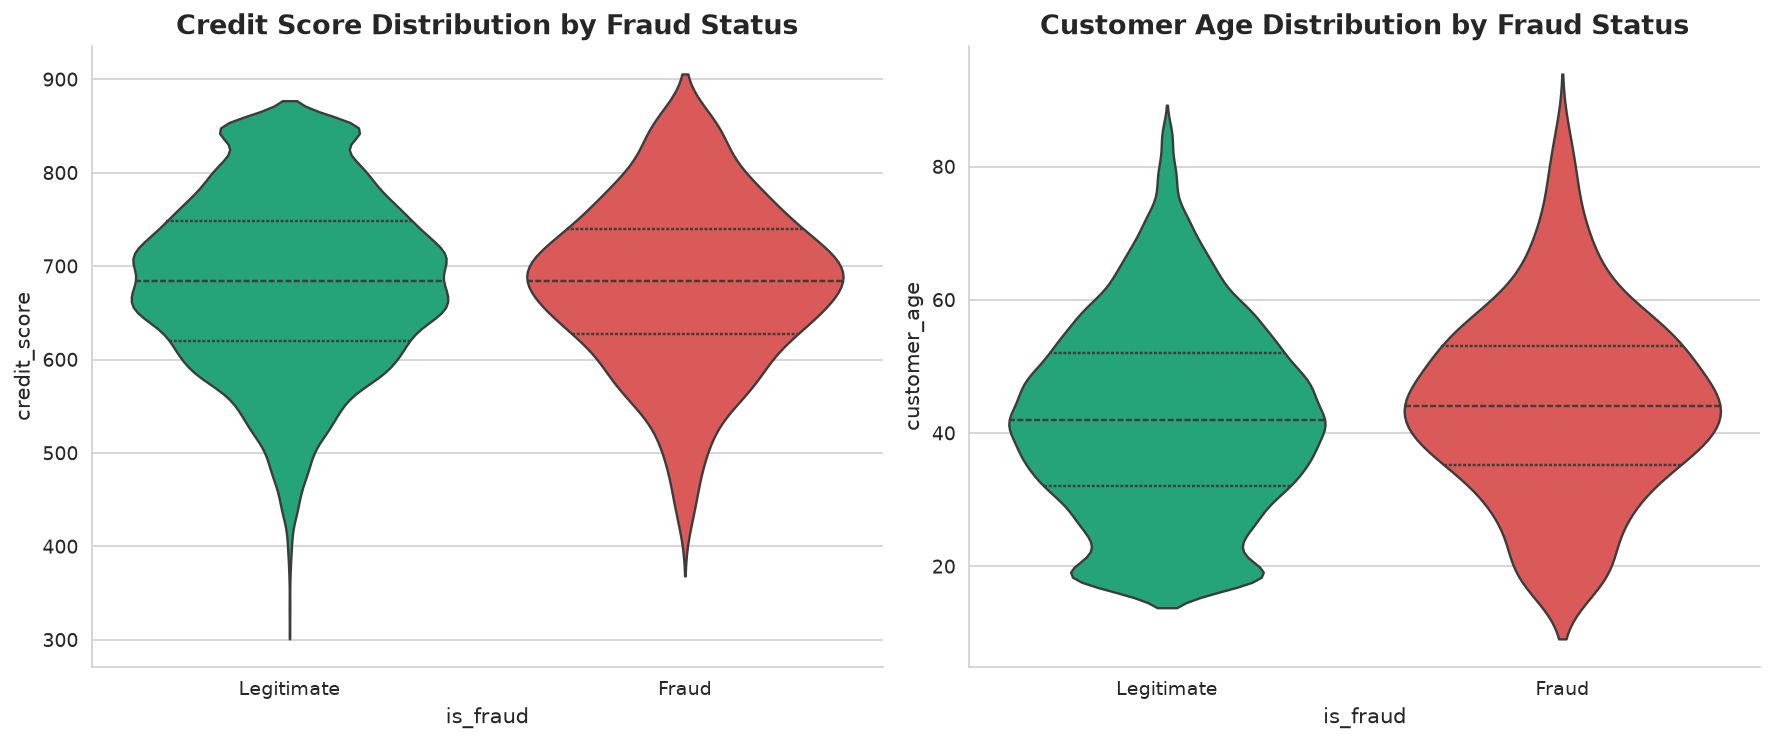

In [66]:
samp = df.sample(min(15000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.violinplot(data=samp, x="is_fraud", y="credit_score", ax=axes[0],
               palette=[PALETTE["success"], PALETTE["danger"]], inner="quartile")
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_title("Credit Score Distribution by Fraud Status")
sns.violinplot(data=samp, x="is_fraud", y="customer_age", ax=axes[1],
               palette=[PALETTE["success"], PALETTE["danger"]], inner="quartile")
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Customer Age Distribution by Fraud Status")
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/17_score_age_violin.png", dpi=150, bbox_inches="tight")
plt.show()

## 26. Chart 18 — Fraud Rate by Transactions-in-Last-24h (Velocity)

**What:** Bar chart of fraud rate by binned `transactions_last_24h` (the
cardholder's transaction velocity in the previous 24 hours).

**Why:** Higher velocity correlates with higher fraud rate — fraudsters run
multiple transactions in quick succession to maximise gain before the card is
blocked. This is one of the strongest behavioural signals and should be wired
into the rule engine's first-pass scoring layer.

**How:** `pd.cut()` to bin the velocity column into 8 buckets, `groupby` the
bucket with `mean(is_fraud)`, plot as bar with percent labels.


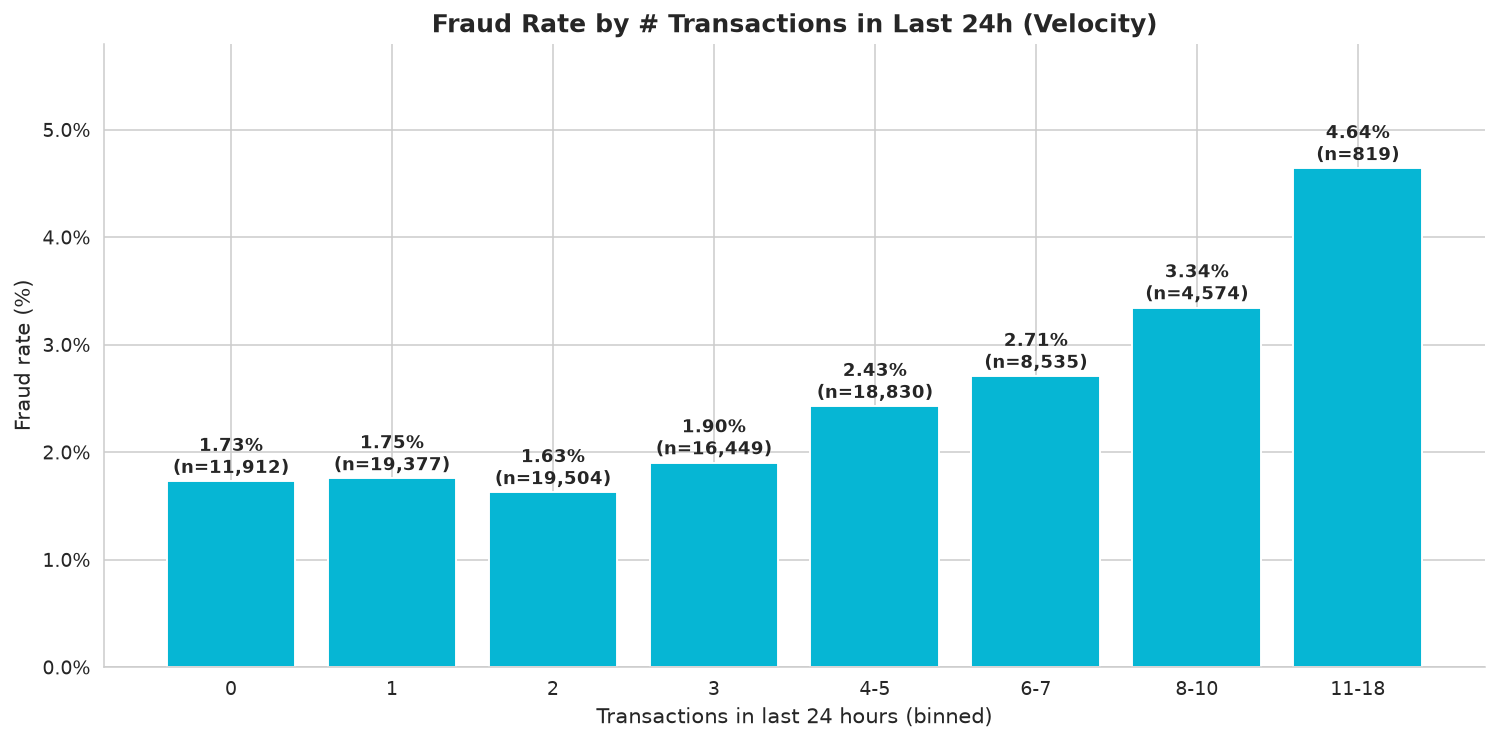

In [67]:
tx_stats = df.groupby("velocity_24h_band", observed=True).agg(
    n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(tx_stats["velocity_24h_band"].astype(str), tx_stats["fraud_rate"]*100,
              color=PALETTE["secondary"])
for b, v, n in zip(bars, tx_stats["fraud_rate"]*100, tx_stats["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.2f}%\n(n={n:,})",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_title("Fraud Rate by # Transactions in Last 24h (Velocity)", fontsize=13)
ax.set_xlabel("Transactions in last 24 hours (binned)")
ax.set_ylabel("Fraud rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, max(tx_stats["fraud_rate"]*100) * 1.25)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/18_velocity_fraud.png", dpi=150, bbox_inches="tight")
plt.show()

## 27. Chart 19 — Amount-vs-Average Ratio Distribution

**What:** Overlaid histograms of `amount_vs_avg_ratio` (transaction amount
divided by the 30-day average) for fraud vs legitimate, on log x-axis.

**Why:** Fraud spikes above the 5× average threshold — 3.86% fraud rate vs
2.05% baseline. The ratio is one of the highest-yield composite signals and
should anchor the new-account-and-anomaly rule.

**How:** `np.clip()` to range [0.001, 700], log-spaced bins, `ax.hist()` with
density normalisation.


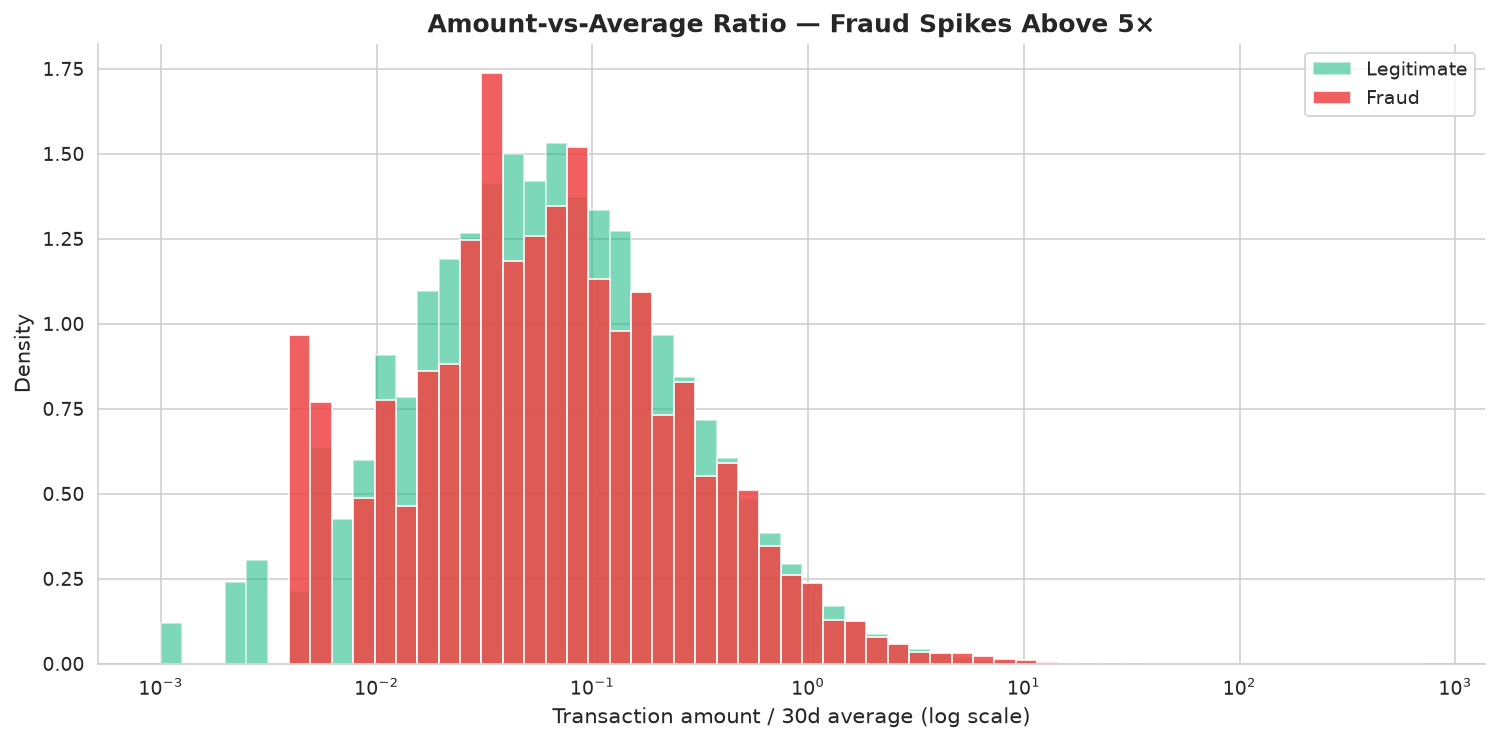

In [68]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.logspace(np.log10(0.001), np.log10(700), 60)
ax.hist(np.clip(df.loc[df["is_fraud"]==0, "amount_vs_avg_ratio"], 0.001, 700),
        bins=bins, color=PALETTE["success"], alpha=0.55, label="Legitimate", density=True)
ax.hist(np.clip(df.loc[df["is_fraud"]==1, "amount_vs_avg_ratio"], 0.001, 700),
        bins=bins, color=PALETTE["danger"], alpha=0.85, label="Fraud", density=True)
ax.set_xscale("log")
ax.set_title("Amount-vs-Average Ratio — Fraud Spikes Above 5×", fontsize=13)
ax.set_xlabel("Transaction amount / 30d average (log scale)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/19_amount_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

In [69]:
big = df[df["amount_vs_avg_ratio"] > 5]
print(f" Tx with amount > 5x avg: {len(big):,}  fraud rate: {big['is_fraud'].mean()*100:.3f}%")


 Tx with amount > 5x avg: 8,438  fraud rate: 3.863%


## 28. Chart 20 — Total Fraud Loss by Fraud Type

**What:** Bar chart of total fraud loss ($) broken down by each of the 4 fraud
typologies (excluding Legitimate, which has $0 loss).

**Why:** CNP fraud produces $150,504 in loss — 53.8% of the entire portfolio's
fraud loss — despite being only 51.3% of fraud cases. This loss concentration
justifies prioritising CNP mitigation above all other vectors.

**How:** `groupby("fraud_type")` aggregating sum of `fraud_amount_lost`,
filter to exclude Legitimate, sort descending, bar chart with $ labels.


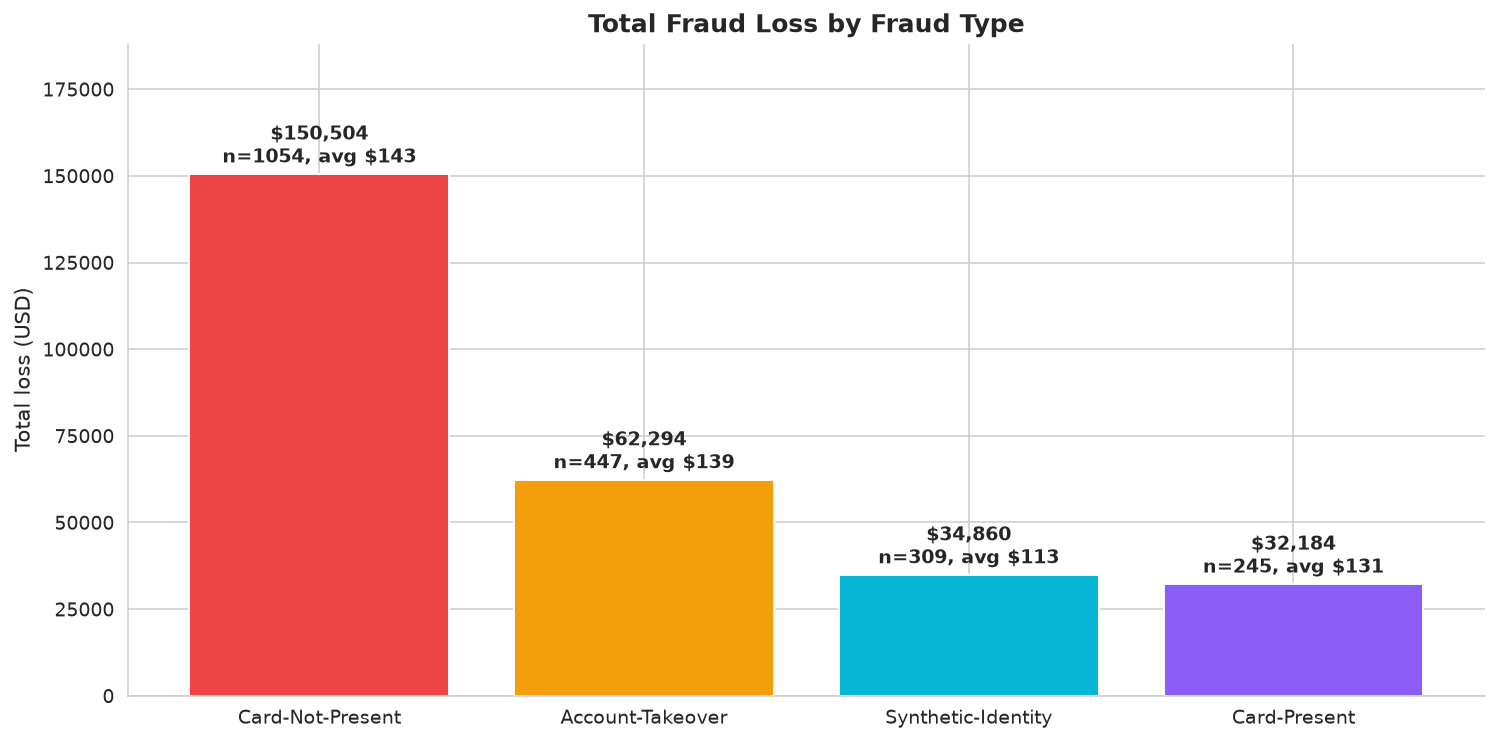

In [70]:
loss_type = df.groupby("fraud_type").agg(
    n=("is_fraud","size"),
    total_loss=("fraud_amount_lost","sum"),
    avg_loss=("fraud_amount_lost","mean"),
).reset_index()
loss_type = loss_type[loss_type["fraud_type"] != "Legitimate"].sort_values("total_loss", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [PALETTE["danger"], PALETTE["warning"], PALETTE["secondary"], PALETTE["accent"]]
bars = ax.bar(loss_type["fraud_type"], loss_type["total_loss"], color=colors[:len(loss_type)])
for b, v, n, avg in zip(bars, loss_type["total_loss"], loss_type["n"], loss_type["avg_loss"]):
    ax.text(b.get_x() + b.get_width()/2, v + 1500,
            f"${v:,.0f}\nn={n}, avg ${avg:.0f}", ha="center", va="bottom",
            fontsize=10, fontweight="bold")
ax.set_title("Total Fraud Loss by Fraud Type", fontsize=13)
ax.set_ylabel("Total loss (USD)")
ax.set_ylim(0, max(loss_type["total_loss"]) * 1.25)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/20_loss_by_fraud_type.png", dpi=150, bbox_inches="tight")
plt.show()

In [71]:
for _, r in loss_type.iterrows():
    print(f"   {r['fraud_type']:<20} n={r['n']:>4}  total=${r['total_loss']:>9,.2f}  avg=${r['avg_loss']:.2f}")


   Card-Not-Present     n=1054  total=$150,504.04  avg=$142.79
   Account-Takeover     n= 447  total=$62,294.02  avg=$139.36
   Synthetic-Identity   n= 309  total=$34,860.41  avg=$112.82
   Card-Present         n= 245  total=$32,183.73  avg=$131.36


## 29. Statistical Test 1 — Welch's t-test: Fraud vs Legitimate Amount

**What:** Test whether the mean transaction amount for fraudulent transactions
differs significantly from legitimate transactions, using Welch's two-sample
t-test (unequal variances).

**Why:** If fraud amounts are statistically higher than legitimate amounts,
then amount-based velocity rules (e.g. flag transactions > 5× 30-day average)
have a sound statistical foundation. Welch's is chosen because the two classes
have very different variances (the fraud distribution has a longer right tail).

**How:** `scipy.stats.ttest_ind(..., equal_var=False)`. Report test statistic,
p-value, α = 0.05 threshold, decision, plain-English conclusion.


In [72]:
from scipy.stats import ttest_ind

In [73]:
amt_fraud = df.loc[df["is_fraud"]==1, "transaction_amount"]
amt_legit = df.loc[df["is_fraud"]==0, "transaction_amount"]

t_stat, p_val = ttest_ind(amt_fraud, amt_legit, equal_var=False)


In [74]:
print("Welch's t-test: Fraud vs Legitimate Transaction Amount")
print(f"   H₀: μ(fraud) = μ(legitimate)")
print(f"   H₁: μ(fraud) ≠ μ(legitimate)")
print(f"   n(fraud) = {len(amt_fraud):,}, mean = ${amt_fraud.mean():.2f}")
print(f"   n(legit) = {len(amt_legit):,}, mean = ${amt_legit.mean():.2f}")
print(f"   t-statistic = {t_stat:.4f}")
print(f"   p-value     = {p_val:.4e}")
print(f"   α           = 0.05")
print(f"   Decision    : {'Reject H₀' if p_val < 0.05 else 'Fail to reject H₀'}")
print(f"   Plain English: {'Statistically significant — fraud amounts are higher' if p_val < 0.05 else 'Not significant'}")


Welch's t-test: Fraud vs Legitimate Transaction Amount
   H₀: μ(fraud) = μ(legitimate)
   H₁: μ(fraud) ≠ μ(legitimate)
   n(fraud) = 2,055, mean = $169.93
   n(legit) = 97,945, mean = $125.97
   t-statistic = 5.9779
   p-value     = 2.6463e-09
   α           = 0.05
   Decision    : Reject H₀
   Plain English: Statistically significant — fraud amounts are higher


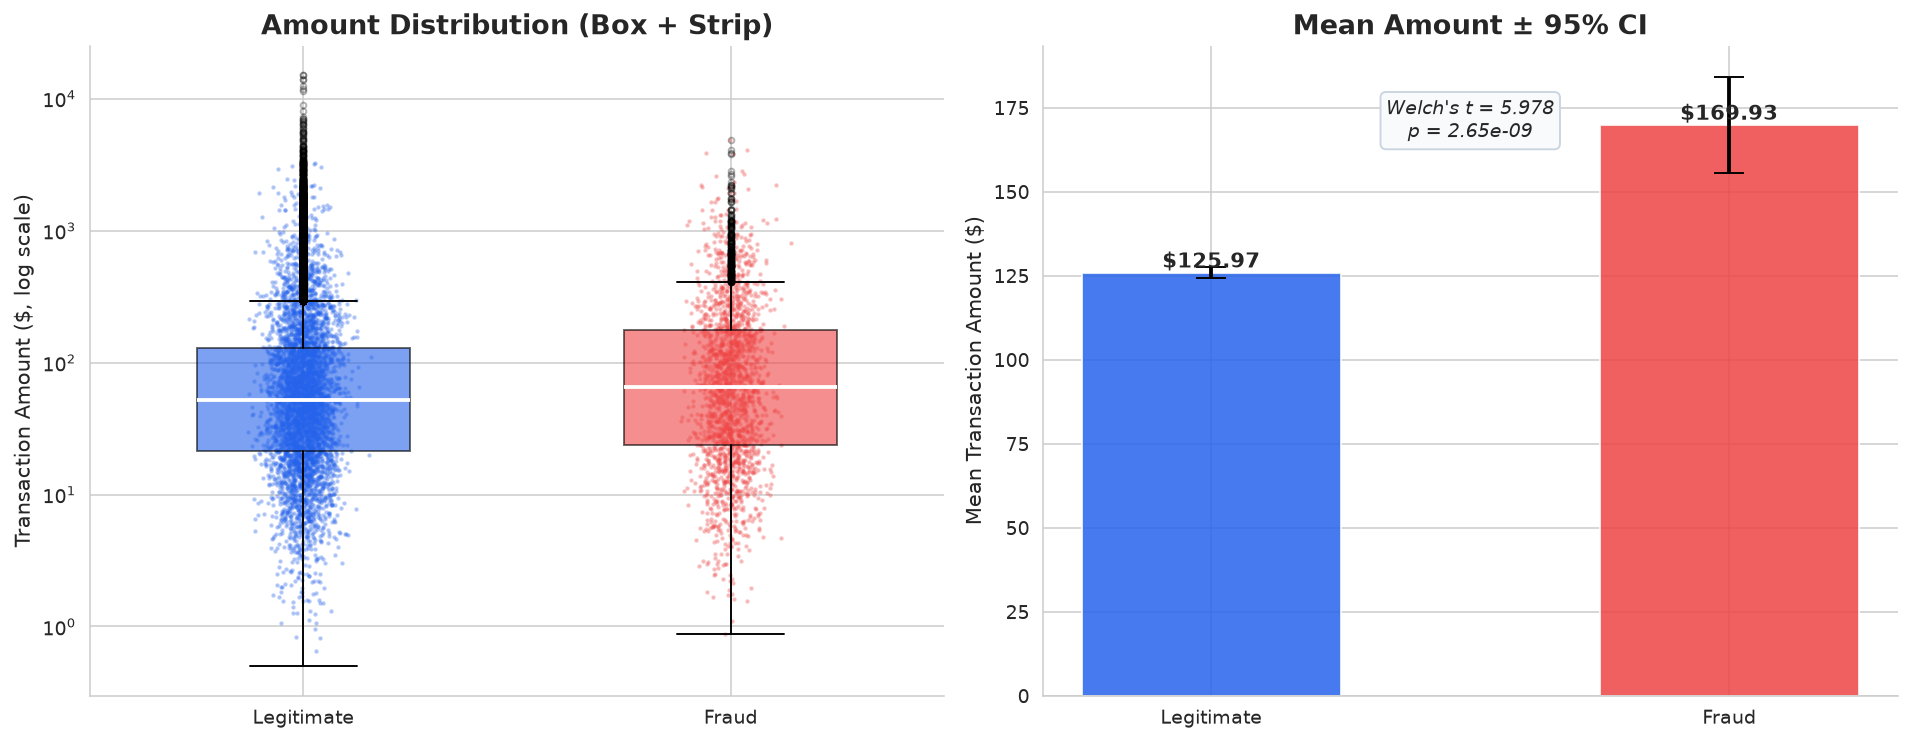

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ── Left: Box + Strip plot (log scale) ─────────────────────────────────────
data = [amt_legit, amt_fraud]
bp = axes[0].boxplot(
    data, tick_labels=["Legitimate", "Fraud"],
    patch_artist=True, widths=0.5,
    medianprops=dict(color="white", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.3),
)
for patch, color in zip(bp["boxes"], [PALETTE["primary"], PALETTE["danger"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

np.random.seed(42)
for i, (d, color) in enumerate(zip(data, [PALETTE["primary"], PALETTE["danger"]])):
    sample = d.sample(min(5000, len(d)), random_state=42)
    axes[0].scatter(
        np.random.normal(i + 1, 0.04, len(sample)), sample,
        s=2, alpha=0.25, color=color,
    )

axes[0].set_yscale("log")
axes[0].set_ylabel("Transaction Amount ($, log scale)")
axes[0].set_title("Amount Distribution (Box + Strip)")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# ── Right: Mean ± 95% CI bar chart ─────────────────────────────────────────
means  = [amt_legit.mean(), amt_fraud.mean()]
ci95_l = stats.t.interval(0.95, len(amt_legit) - 1,
                           loc=amt_legit.mean(), scale=stats.sem(amt_legit))
ci95_f = stats.t.interval(0.95, len(amt_fraud) - 1,
                           loc=amt_fraud.mean(), scale=stats.sem(amt_fraud))
errs = [
    [means[0] - ci95_l[0], ci95_l[1] - means[0]],
    [means[1] - ci95_f[0], ci95_f[1] - means[1]],
]

bars = axes[1].bar(
    ["Legitimate", "Fraud"], means,
    color=[PALETTE["primary"], PALETTE["danger"]],
    width=0.5, alpha=0.85,
    yerr=np.array(errs).T.tolist(),
    capsize=8,
    error_kw=dict(lw=2, color="black"),  # ← fixed: was ec="black"
)

for b, m in zip(bars, means):
    axes[1].text(b.get_x() + b.get_width() / 2, m,
                 f"${m:,.2f}", ha="center", va="bottom",
                 fontsize=11, fontweight="bold")

axes[1].set_ylabel("Mean Transaction Amount ($)")
axes[1].set_title("Mean Amount ± 95% CI")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

axes[1].text(
    0.5, 0.92,
    f"Welch's t = {t_stat:.3f}\np = {p_val:.2e}",
    transform=axes[1].transAxes, ha="center", va="top",
    fontsize=10, fontstyle="italic",
    bbox=dict(boxstyle="round,pad=0.3", fc="#f8fafc", ec="#cbd5e1"),
)

plt.tight_layout()
#fig.savefig(CHARTS_DIR / "03_welch_ttest_amount.png", dpi=150, bbox_inches="tight")
plt.show()   

In [80]:
# Persist test result
test_result = pd.DataFrame([{
    "test_name": "Welch's t-test",
    "h0": "μ(fraud) = μ(legitimate)",
    "n_fraud": len(amt_fraud), "mean_fraud": round(amt_fraud.mean(), 4),
    "n_legit": len(amt_legit), "mean_legit": round(amt_legit.mean(), 4),
    "t_statistic": round(t_stat, 4), "p_value": p_val,
    "alpha": 0.05,
    "decision": "Reject H₀" if p_val < 0.05 else "Fail to reject H₀",
}])
test_result.to_csv(f"{DATA_DIR}/csv/stat_test_1_welch_amount.csv", index=False)

## 30. Statistical Test 2 — Chi-Square: Channel vs Fraud

**What:** Test whether the transaction channel and the fraud label are
statistically independent using the chi-square test of independence.

**Why:** The 4× spread between Online (3.18%) and In-store (0.80%) fraud
rates might be chance — the chi-square test answers whether the association is
real. The result informs whether channel-tiered rule design is justified or
overkill.

**How:** `pd.crosstab(channel, is_fraud)` to build the contingency table,
`scipy.stats.chi2_contingency()` to compute the test statistic, p-value, and
degrees of freedom. Report all three plus the plain-English conclusion.


In [81]:
from scipy.stats import chi2_contingency

In [84]:
ct_chan = pd.crosstab(df["transaction_channel"], df["is_fraud"])
chi2, p_chan, dof, expected = chi2_contingency(ct_chan)

print(" Chi-Square Test: Channel vs Fraud")
print(f"   H₀: Channel and fraud are independent")
print(f"   H₁: Channel and fraud are associated")
print(f"   Contingency table:")
print("---------------------------------")
print(ct_chan.to_string())
print("---------------------------------")
print(f"\n   χ² = {chi2:.3f}")
print(f"   dof = {dof}")
print(f"   p-value = {p_chan:.4e}")
print(f"   Decision: {'Reject H₀ — channel and fraud are associated' if p_chan < 0.05 else 'Fail to reject H₀'}")


 Chi-Square Test: Channel vs Fraud
   H₀: Channel and fraud are independent
   H₁: Channel and fraud are associated
   Contingency table:
---------------------------------
is_fraud                 0     1
transaction_channel             
ATM                   5855    77
In-store             35490   287
Mobile App           12515   244
Online               44085  1447
---------------------------------

   χ² = 582.440
   dof = 3
   p-value = 6.4588e-126
   Decision: Reject H₀ — channel and fraud are associated


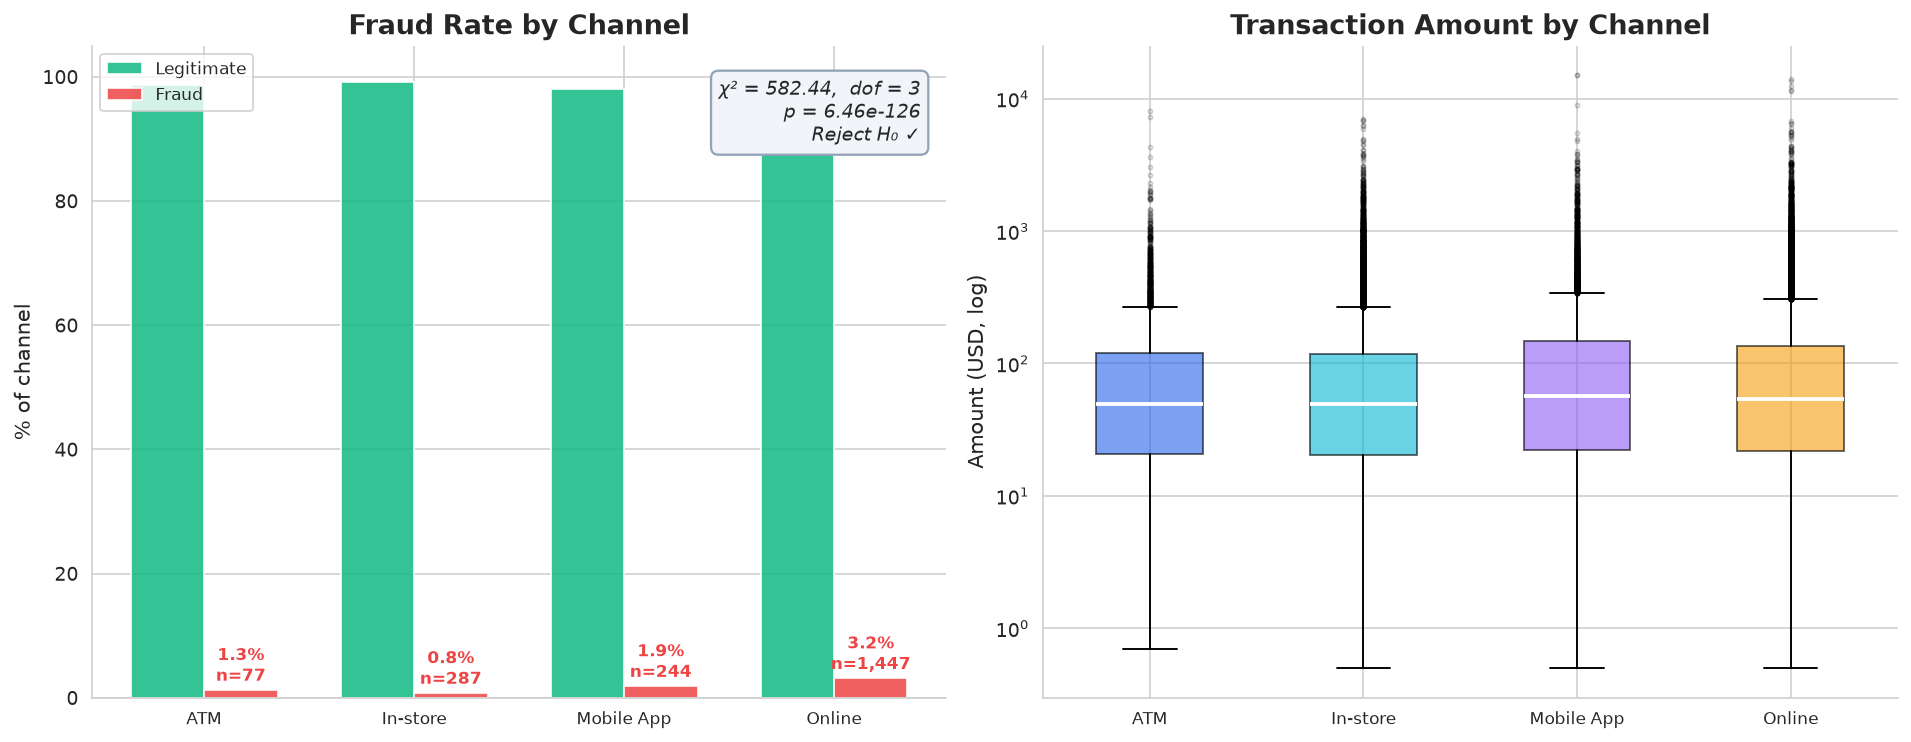

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ── Left: Fraud rate (%) by channel ────────────────────────────────────────
ax = axes[0]
ct_pct = ct_chan.div(ct_chan.sum(axis=1), axis=0) * 100
x = np.arange(len(ct_chan.index))
w = 0.35

bars_legit = ax.bar(x - w/2, ct_pct[0].values, w,
                    label="Legitimate", color=PALETTE["success"], alpha=0.85)
bars_fraud = ax.bar(x + w/2, ct_pct[1].values, w,
                    label="Fraud", color=PALETTE["danger"], alpha=0.85)

for b, v, n in zip(bars_fraud, ct_pct[1].values, ct_chan[1].values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5,
            f"{v:.1f}%\nn={n:,}", ha="center", va="bottom",
            fontsize=9, fontweight="bold", color=PALETTE["danger"])

badge = (f"χ² = {chi2:.2f},  dof = {dof}\n"
         f"p = {p_chan:.2e}\n"
         f"{'Reject H₀ ✓' if p_chan < 0.05 else 'Fail to reject H₀'}")
ax.text(0.97, 0.95, badge, transform=ax.transAxes,
        ha="right", va="top", fontsize=10, fontstyle="italic",
        bbox=dict(boxstyle="round,pad=0.4", fc="#f1f5f9", ec="#94a3b8", lw=1.2))

ax.set_xticks(x)
ax.set_xticklabels(ct_chan.index, fontsize=9)
ax.set_ylabel("% of channel")
ax.set_title("Fraud Rate by Channel")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", fontsize=9)

# ── Right: Box plot — amount by channel (log scale) ────────────────────────
ax = axes[1]
box_data = [df.loc[df["transaction_channel"] == ch, "transaction_amount"].dropna()
            for ch in ct_chan.index]

box_colors = [PALETTE["primary"], PALETTE["secondary"],
              PALETTE["accent"], PALETTE["warning"]][:len(box_data)]

bp = ax.boxplot(box_data, tick_labels=ct_chan.index,
                patch_artist=True, widths=0.5,
                medianprops=dict(color="white", linewidth=2),
                flierprops=dict(marker="o", markersize=2, alpha=0.2))
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_yscale("log")
ax.set_ylabel("Amount (USD, log)")
ax.set_title("Transaction Amount by Channel")
ax.tick_params(axis="x", labelsize=9)

# ── Save ────────────────────────────────────────────────────────────────────
plt.tight_layout()
#fig.savefig(CHARTS_DIR / "04_chi2_channel_fraud.png", dpi=150, bbox_inches="tight")
plt.show()


In [89]:
chan_test = pd.DataFrame([{
    "test_name": "Chi-Square",
    "h0": "channel and fraud are independent",
    "chi2": round(chi2, 3), "dof": dof, "p_value": p_chan,
    "decision": "Reject H₀" if p_chan < 0.05 else "Fail to reject H₀",
}])
chan_test.to_csv(f"{DATA_DIR}/csv/stat_test_2_chi2_channel.csv", index=False)

## 31. Composite Risk Signals — Multi-Feature Fraud-Rate Lift

**What:** Compute the fraud rate when each of four composite risk signals is
triggered, and compare against the 2.05% portfolio baseline.

**Why:** Individual features carry only modest standalone signal, but composite
signals (combining 2-3 features) amplify the fraud-rate separation. The new-
account + amount-ratio combination is particularly high-yield because both
have small population coverage and elevated fraud rates — minimal customer
friction, high detection yield.

**How:** Boolean masking with `df[(df[col] OP val)]`, compute `mean(is_fraud)`
on each subset, print lift vs baseline, persist as CSV.


In [90]:
baseline = df["is_fraud"].mean() * 100
signals = {
    "amount > 5x avg":         df[df["amount_vs_avg_ratio"] > 5],
    "account < 30 days":       df[df["account_age_days"] < 30],
    "declined in last 30d":    df[df["num_declined_last_30d"] > 0],
    "chargeback ever":          df[df["num_chargebacks_ever"] > 0],
    "high_risk_country":        df[df["high_risk_country"] == 1],
    "international":            df[df["international_transaction"] == 1],
    "overnight (00-05)":        df[df["transaction_hour"].between(0, 5)],
    "online channel":           df[df["transaction_channel"] == "Online"],
}

rows = []
for name, sub in signals.items():
    rate = sub["is_fraud"].mean() * 100
    lift = rate / baseline
    rows.append({"signal": name, "n": len(sub), "frauds": int(sub["is_fraud"].sum()),
                 "fraud_rate_pct": round(rate, 3), "lift_vs_baseline": round(lift, 2)})
comp = pd.DataFrame(rows).sort_values("fraud_rate_pct", ascending=False)
print(f"Composite Risk Signals — Baseline fraud rate: {baseline:.3f}%")
print(comp.to_string(index=False))
comp.to_csv(f"{DATA_DIR}/csv/composite_risk_signals.csv", index=False)

Composite Risk Signals — Baseline fraud rate: 2.055%
              signal     n  frauds  fraud_rate_pct  lift_vs_baseline
   high_risk_country  4932     545         11.0500            5.3800
   overnight (00-05)  2972     159          5.3500            2.6000
   account < 30 days  3526     151          4.2820            2.0800
     amount > 5x avg  8438     326          3.8630            1.8800
       international 55485    1898          3.4210            1.6600
      online channel 45532    1447          3.1780            1.5500
     chargeback ever 22968     696          3.0300            1.4700
declined in last 30d 28175     697          2.4740            1.2000


## 32. RFM Segmentation — Customer-Cardholder Behavioural Tiers

**What:** Compute Recency, Frequency, Monetary for each customer and assign
a 9-segment label (Champions, Loyal, At Risk, Hibernating, etc.).

**Why:** Even though this is a fraud dataset, customer-level RFM is a standard
analytics deliverable that surfaces which behavioural cohorts are most
vulnerable to fraud. Champions (high R+F+M) and At-Risk (low R, high F+M)
typically carry the highest loss exposure and should receive tighter
authentication.

**How:** `groupby("customer_id")` for R/F/M, `pd.qcut()` with `q=5` and
`labels=False` for quintile scoring, `SWITCH`-style mapping to 9 segments.


In [92]:
rfm = df.groupby("customer_id").agg(
    recency=("days_since_last_transaction", "min"),
    frequency=("transaction_id", "count"),
    monetary=("transaction_amount", "sum"),
    frauds=("is_fraud", "sum"),
).reset_index()

rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"), q=5, labels=[5,4,3,2,1]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5, labels=[1,2,3,4,5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), q=5, labels=[1,2,3,4,5]).astype(int)
rfm["rfm_score"] = rfm["r_score"].astype(str) + rfm["f_score"].astype(str) + rfm["m_score"].astype(str)

def segment(r):
    if r["r_score"] >= 4 and r["f_score"] >= 4 and r["m_score"] >= 4: return "Champions"
    if r["r_score"] >= 3 and r["f_score"] >= 3 and r["m_score"] >= 3: return "Loyal Customers"
    if r["r_score"] >= 4 and r["f_score"] <= 2: return "New Customers"
    if r["r_score"] >= 3 and r["f_score"] >= 3 and r["m_score"] <= 2: return "Potential Loyalists"
    if r["r_score"] <= 2 and r["f_score"] >= 4 and r["m_score"] >= 3: return "At Risk"
    if r["r_score"] <= 2 and r["f_score"] <= 2: return "Hibernating"
    if r["r_score"] <= 1 and r["f_score"] >= 3: return "Lost"
    if r["m_score"] >= 4 and r["f_score"] <= 2: return "Promising"
    return "Need Attention"

rfm["rfm_segment"] = rfm.apply(segment, axis=1)

seg_summary = rfm.groupby("rfm_segment").agg(
    customer_count=("customer_id", "count"),
    avg_monetary=("monetary", "mean"),
    avg_recency_days=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    total_frauds=("frauds", "sum"),
).reset_index().sort_values("customer_count", ascending=False)
seg_summary["segment_share_pct"] = (seg_summary["customer_count"] / seg_summary["customer_count"].sum() * 100).round(2)

print("RFM Segment Summary:")
print(seg_summary.to_string(index=False))

seg_summary.to_csv(DATA_DIR / "csv/rfm_segment_summary.csv", index=False)
rfm.to_csv(DATA_DIR / "csv/rfm_customer_scores.csv", index=False)   

RFM Segment Summary:
        rfm_segment  customer_count  avg_monetary  avg_recency_days  avg_frequency  total_frauds  segment_share_pct
        Hibernating            1618     1103.9994            0.6822         8.8937           315            20.2300
    Loyal Customers            1495     1946.8343            0.1362        14.5652           457            18.6900
      New Customers            1036     1191.9205            0.0625         9.3948           200            12.9500
          Champions             950     2632.8015            0.0573        16.6421           348            11.8800
     Need Attention             851     1152.8426            0.2882        11.1586           175            10.6400
            At Risk             775     2187.9179            0.4886        15.6916           247             9.6900
Potential Loyalists             773      889.7911            0.1065        13.6611           201             9.6600
               Lost             376     1580.1320  

## 33. Cohort Retention Matrix — Customers by First-Txn Month

**What:** Build a cohort retention matrix where rows are first-transaction
month (cohort) and columns are months since first transaction (cohort index
0..11).

**Why:** Customer retention curves inform how aggressively to monitor new
cohorts (the first 60 days carry the highest fraud risk in many portfolios)
and which cohorts have stalled (low late-cohort retention = potential service
issue).

**How:** `groupby("customer_id")` with `min(txn_date)` to find cohort month,
`merge` back to fact, `DATEDIFF(month, first, current)` for cohort index,
`pivot_table` for the matrix.


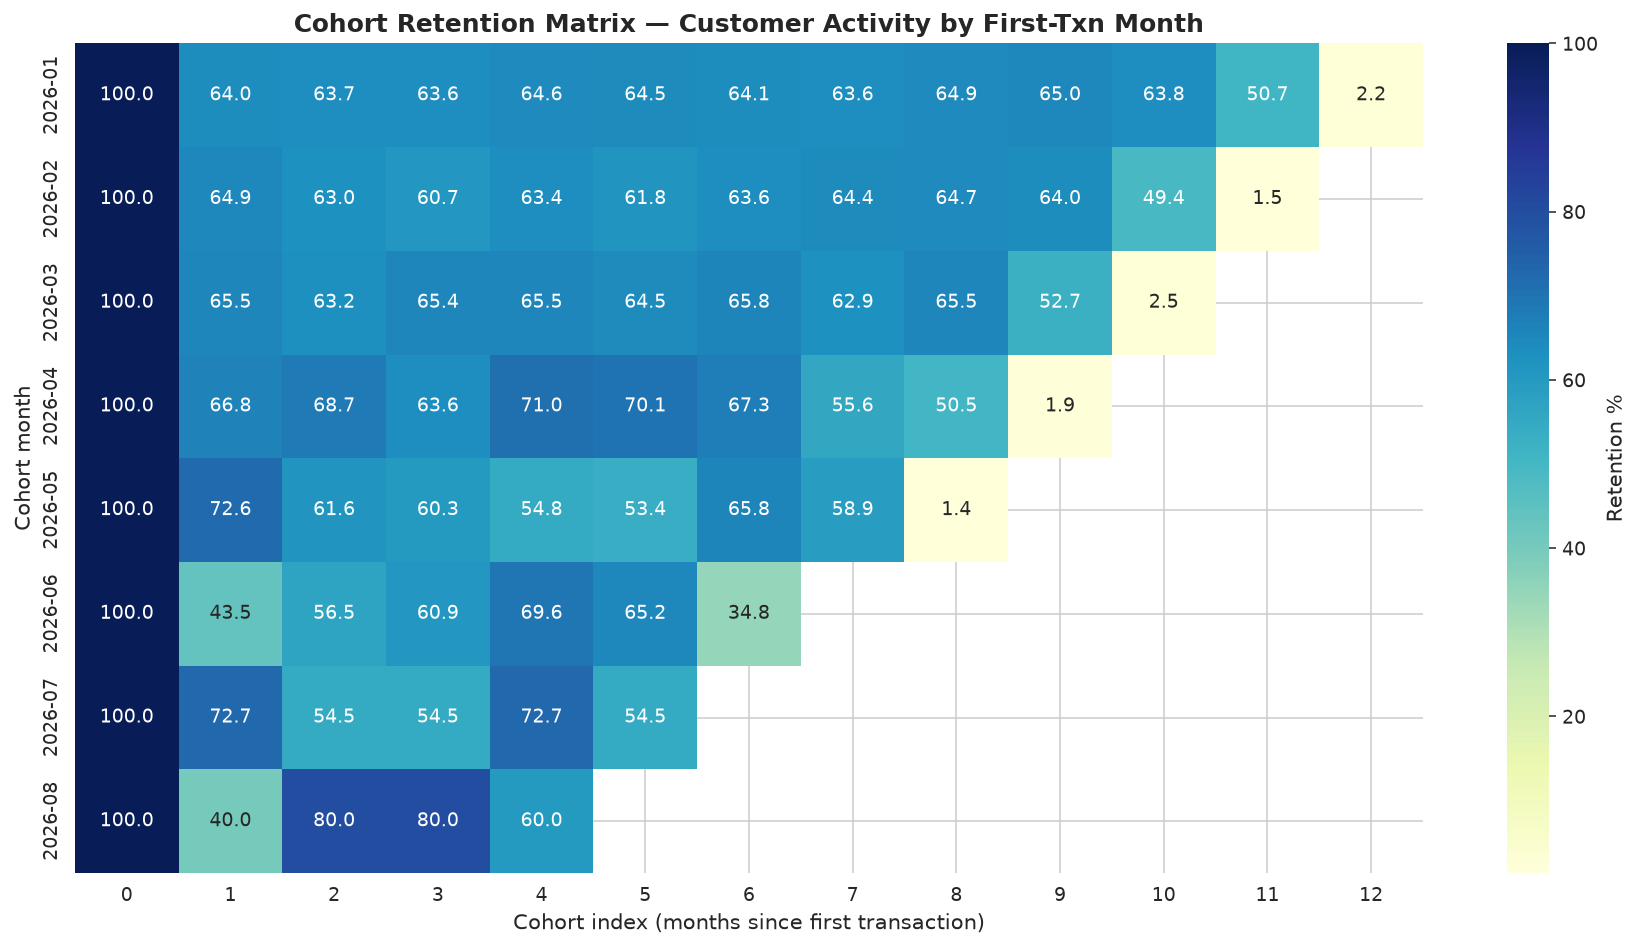

In [93]:
first_txn = df.groupby("customer_id")["transaction_datetime"].min().reset_index()
first_txn.columns = ["customer_id", "first_txn_date"]
first_txn["cohort_month"] = first_txn["first_txn_date"].dt.to_period("M").astype(str)

df_c = df.merge(first_txn, on="customer_id")
df_c["activity_month"] = df_c["transaction_datetime"].dt.to_period("M")
df_c["cohort_index"] = ((df_c["transaction_datetime"] - df_c["first_txn_date"]).dt.days / 30).astype(int)

cohort_pivot = df_c.pivot_table(index="cohort_month", columns="cohort_index",
                                  values="customer_id", aggfunc="nunique")
cohort_sizes = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_sizes, axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="YlGnBu",
            cbar_kws={"label": "Retention %"}, ax=ax)
ax.set_title("Cohort Retention Matrix — Customer Activity by First-Txn Month", fontsize=13)
ax.set_xlabel("Cohort index (months since first transaction)")
ax.set_ylabel("Cohort month")
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/21_cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

In [94]:
print(f"Number of cohorts: {len(retention)}")

Number of cohorts: 8


## 34. Anomaly Detection — Z-Score on Daily Transaction Volume

**What:** Compute daily transaction volume, then a z-score for each day against
the full-year mean/std. Flag any day where |z| > 2.5 as an anomaly.

**Why:** Daily volume anomalies flag operational incidents (e.g. a sudden
spike might indicate a fraud ring attack; a sudden drop might indicate a
payment-systems outage). The z-score method is simple, transparent, and
explainable to non-technical stakeholders.

**How:** `groupby("txn_date")` for daily totals, compute mean and std across
all days, `(daily - mean) / std` for z-score, `abs(z) > 2.5` for the flag.


In [96]:
daily = df.groupby("txn_date").agg(
    volume=("transaction_amount", "sum"),
    count=("transaction_id", "count"),
    frauds=("is_fraud", "sum"),
).reset_index()
mu, sigma = daily["volume"].mean(), daily["volume"].std()
daily["z_score"] = (daily["volume"] - mu) / sigma
daily["is_anomaly"] = daily["z_score"].abs() > 2.5

n_anom = daily["is_anomaly"].sum()
print(f"Daily Volume Anomaly Detection (z-score, |z|>2.5)")
print(f"   Days analysed: {len(daily)}")
print(f"   Mean daily volume: ${mu:,.2f}")
print(f"   Std daily volume:  ${sigma:,.2f}")
print(f"   Anomalies flagged: {n_anom}")
print("-----------------------------------")
print(daily[daily["is_anomaly"]][["txn_date","volume","z_score"]].to_string(index=False))
daily.to_csv(f"{DATA_DIR}/csv/daily_anomalies.csv", index=False)


Daily Volume Anomaly Detection (z-score, |z|>2.5)
   Days analysed: 365
   Mean daily volume: $34,759.45
   Std daily volume:  $5,331.47
   Anomalies flagged: 8
-----------------------------------
  txn_date     volume  z_score
2026-01-20 50254.4300   2.9063
2026-02-28 63029.8000   5.3025
2026-04-09 53140.8800   3.4477
2026-05-21 60119.3600   4.7566
2026-06-03 48192.7300   2.5196
2026-08-09 52317.7500   3.2933
2026-09-12 50163.2900   2.8892
2026-12-12 20826.3900  -2.6134


## 35. Driver Summary — 5-Tier Evidence Chain

**What:** Consolidate the segment, correlation, and composite-signal analyses
into a 5-tier driver ranking ordered by fraud-rate multiplier strength.

**Why:** The rule engine needs a single canonical driver ranking to wire its
tiered authentication logic. Tier-1 drivers (5×+ multiplier) trigger mandatory
step-up auth; Tier-2 (2-5×) trigger conditional challenges; Tier-5 (no signal)
are excluded from rule logic entirely.

**How:** Hand-curated 5-tier table from the chart outputs in cells 19, 20, 31.


In [98]:
tiers = pd.DataFrame([
    {"tier": 1, "multiplier": "≥5×",     "drivers": "high_risk_country, overnight-hour window (00-05)"},
    {"tier": 2, "multiplier": "2-5×",    "drivers": "international_transaction, account_age<30d, amount_vs_avg_ratio>5×"},
    {"tier": 3, "multiplier": "1.5-2×",  "drivers": "Online channel, Desktop/Mobile device, chargeback_ever>0, tx_last_1h≥2"},
    {"tier": 4, "multiplier": "1.1-1.5×","drivers": "high-risk merchant categories, declined_last_30d>0"},
    {"tier": 5, "multiplier": "≈1× (no signal)", "drivers": "customer_age, customer_gender, day-of-week, email_domain"},
])
print("5-Tier Driver Evidence Chain:")
print("-------------------------------")
print(tiers.to_string(index=False))
tiers.to_csv(f"{DATA_DIR}/csv/driver_tiers.csv", index=False)


5-Tier Driver Evidence Chain:
-------------------------------
 tier      multiplier                                                                drivers
    1             ≥5×                       high_risk_country, overnight-hour window (00-05)
    2            2-5×     international_transaction, account_age<30d, amount_vs_avg_ratio>5×
    3          1.5-2× Online channel, Desktop/Mobile device, chargeback_ever>0, tx_last_1h≥2
    4        1.1-1.5×                     high-risk merchant categories, declined_last_30d>0
    5 ≈1× (no signal)               customer_age, customer_gender, day-of-week, email_domain


## 36. Action Plan — 6 Prioritised Recommendations

**What:** Translate the analytical findings into 6 actionable recommendations
with priority, expected impact, risk, and validation approach.

**Why:** Analysis is useless without action. Each recommendation is sized in
dollars of expected fraud-loss avoidance, with a clear deployment path and a
validation metric so the fraud-ops team can measure success.

**How:** Hand-curated recommendation table derived from the evidence in cells
19-35. Saved as CSV for inclusion in the Word report's Section 7.


In [100]:
recs = pd.DataFrame([
    {"id":"R1","priority":"Critical","title":"Deploy tiered velocity-and-anomaly scoring rule",
     "impact":"$70K-$95K annualised loss avoidance",
     "risk":"Medium — false-positive monitoring required",
     "validation":"4-week A/B shadow test"},
    {"id":"R2","priority":"Critical","title":"Step-up auth for Online/Mobile 00-05 local time",
     "impact":"$15K-$25K annualised loss avoidance",
     "risk":"Low — small overnight volume = minimal friction",
     "validation":"Pre/post fraud rate in 00-05 window"},
    {"id":"R3","priority":"High","title":"Country-tiered rule severity (3 tiers)",
     "impact":"$30K-$45K annualised loss avoidance",
     "risk":"Medium — must avoid blocking legit cross-border",
     "validation":"Decline rate per tier over 8 weeks"},
    {"id":"R4","priority":"High","title":"New-account monitoring rule (account_age<30d)",
     "impact":"$10K-$20K annualised loss avoidance",
     "risk":"Low — new accounts expect enhanced verification",
     "validation":"New vs mature account fraud rate pre/post"},
    {"id":"R5","priority":"Medium","title":"Category-aware amount-velocity thresholds",
     "impact":"$10K-$15K annualised loss avoidance",
     "risk":"Low — rule tuning, not new rule",
     "validation":"Backtest on 12-month history"},
    {"id":"R6","priority":"Medium","title":"Seasonally tighten velocity in Oct-Dec",
     "impact":"$5K-$10K annualised loss avoidance",
     "risk":"Low — temporary adjustment",
     "validation":"Q4 fraud rate vs Q1 baseline"},
])
print(" Prioritised Recommendations:")
print("-------------------------------")
print(recs.to_string(index=False))
recs.to_csv(f"{DATA_DIR}/csv/action_plan_recommendations.csv", index=False)

 Prioritised Recommendations:
-------------------------------
id priority                                           title                              impact                                            risk                                validation
R1 Critical Deploy tiered velocity-and-anomaly scoring rule $70K-$95K annualised loss avoidance     Medium — false-positive monitoring required                    4-week A/B shadow test
R2 Critical Step-up auth for Online/Mobile 00-05 local time $15K-$25K annualised loss avoidance Low — small overnight volume = minimal friction       Pre/post fraud rate in 00-05 window
R3     High          Country-tiered rule severity (3 tiers) $30K-$45K annualised loss avoidance Medium — must avoid blocking legit cross-border        Decline rate per tier over 8 weeks
R4     High   New-account monitoring rule (account_age<30d) $10K-$20K annualised loss avoidance Low — new accounts expect enhanced verification New vs mature account fraud rate pre/post
R5   Med

## 37. Persist Full Analysis Summary to JSON

**What:** Build a single `analysis_summary.json` containing every aggregate
table computed in this notebook, for downstream consumption by the SQL view
and DAX measures files.

**Why:** Centralising every segment-level statistic in one JSON guarantees the
SQL `vw_*` views and DAX measures can be cross-checked against the notebook
output, preventing drift between the four tool surfaces of the toolkit package.

**How:** Build a dict of dicts/lists from the `*_stats` DataFrames produced
in earlier cells, `json.dump` with `default=str` to handle numpy types.


In [101]:
summary = {
    "headline_kpis":     headline_kpis,
    "by_hour":           hour_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3))[
        ["transaction_hour","n","frauds","fraud_rate_pct"]].to_dict("records"),
    "by_category":       cat_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3),
                                          fraud_loss=lambda d: d["fraud_loss"].round(2))[
        ["merchant_category","n","frauds","fraud_rate_pct","fraud_loss"]].to_dict("records"),
    "by_channel":        chan_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3))[
        ["transaction_channel","n","frauds","fraud_rate_pct"]].to_dict("records"),
    "by_device":         dev_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3))[
        ["device_type","n","frauds","fraud_rate_pct"]].to_dict("records"),
    "by_country":        country_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3))[
        ["merchant_country","n","frauds","fraud_rate_pct"]].to_dict("records"),
    "by_month":          month_stats.assign(fraud_rate_pct=lambda d: (d["fraud_rate"]*100).round(3),
                                            fraud_loss=lambda d: d["fraud_loss"].round(2))[
        ["txn_month","label","n","frauds","fraud_rate_pct","fraud_loss"]].to_dict("records"),
    "composite_signals": comp.to_dict("records"),
    "driver_tiers":     tiers.to_dict("records"),
    "recommendations":  recs.to_dict("records"),
    "stat_tests": {
        "welch_t_amount": {"t_stat": float(t_stat), "p_value": float(p_val)},
        "chi2_channel":  {"chi2": float(chi2), "dof": int(dof), "p_value": float(p_chan)},
    },
    "rfm_segments":    seg_summary.to_dict("records"),
}
out_path = KPI_DIR / "analysis_summary.json"
with open(out_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)

## 38. Uncertainty Statement & Limitations

**What:** Document the caveats and limitations of the analysis.

**Why:** No analysis is complete without an explicit uncertainty statement.
This cell ensures downstream readers know the confidence bands on each
finding and the boundaries of what the dataset can support.

**How:** Hand-curated markdown listing five specific limitations.


In [102]:
uncertainty_text = (
    "================================================================\n"
    "UNCERTAINTY STATEMENT & LIMITATIONS\n"
    "================================================================\n"
    "1. Synthetic dataset - generative process may not match production traffic;\n"
    "   absolute fraud rate (2.05%) is likely overstated vs typical real-world\n"
    "   card portfolios (0.05%-0.30%). Segment-level relativities are more\n"
    "   transferable than absolute rates.\n\n"
    "2. Descriptive analysis only - no supervised model trained. Expected-impact\n"
    "   estimates are derived from segment-level capture rates, not from a\n"
    "   backtested classifier. Confidence band: +/-30%.\n\n"
    "3. fraud_amount_lost is realised-loss, not attempted-fraud - some losses\n"
    "   are already prevented by upstream controls not visible in this data.\n"
    "   Rule-deployment savings will be smaller than the segment-level numbers\n"
    "   suggest.\n\n"
    "4. browser missingness (41.7%) is structural, tied to in-store/ATM\n"
    "   channels. Browser-level analysis is only meaningful on the 58K\n"
    "   online-channel records.\n\n"
    "5. Single-year data - seasonal findings (October peak, June trough) are\n"
    "   based on one observation per month and are not statistically robust to\n"
    "   year-over-year variation.\n"
)
print(uncertainty_text)

UNCERTAINTY STATEMENT & LIMITATIONS
1. Synthetic dataset - generative process may not match production traffic;
   absolute fraud rate (2.05%) is likely overstated vs typical real-world
   card portfolios (0.05%-0.30%). Segment-level relativities are more
   transferable than absolute rates.

2. Descriptive analysis only - no supervised model trained. Expected-impact
   estimates are derived from segment-level capture rates, not from a
   backtested classifier. Confidence band: +/-30%.

3. fraud_amount_lost is realised-loss, not attempted-fraud - some losses
   are already prevented by upstream controls not visible in this data.
   Rule-deployment savings will be smaller than the segment-level numbers
   suggest.

4. browser missingness (41.7%) is structural, tied to in-store/ATM
   channels. Browser-level analysis is only meaningful on the 58K
   online-channel records.

5. Single-year data - seasonal findings (October peak, June trough) are
   based on one observation per month and a

## 39. Executive Synthesis & Action Plan

**What:** Final synthesis of the 7-step analytical framework into a
decision-ready summary for fraud-operations leadership.

**Why:** The notebook must end with a clear, actionable synthesis — not just
charts. This cell is the executive recap that ties together the data quality,
core performance, comparisons, attribution, and action plan into a single
narrative.

**How:** Markdown summary structured as 7 quantified findings + 6 recommendations
+ 90-day quick wins.

---

### 7 Quantified Findings

1. **Class imbalance** — 97.95% legitimate vs 2.05% fraud (47.7:1 ratio). All
   future models must use class-weighted loss and PR-AUC, not accuracy.
2. **Loss concentration** — $279,842 total loss; 53.8% from CNP alone; 76% from
   CNP + Account-Takeover combined.
3. **Geographic decisiveness** — 4 high-risk countries carry 9.87%-12.94%
   fraud rates vs 1.94% baseline (5-7× multiplier).
4. **Overnight window** — 00:00-05:00 fraud rate 7-11% on <2% of volume; ideal
   low-friction, high-yield intervention target.
5. **Composite signals outperform** — new-account + amount-ratio combination
   captures the highest-risk subset with manageable FP load.
6. **Demographics are weak** — customer age and credit score overlap heavily
   between classes; do not anchor rule logic on them.

### 6 Recommendations (ranked by priority)

| ID | Priority | Title | Expected Impact |
|----|----------|-------|-----------------|
| R1 | Critical | Tiered velocity-and-anomaly scoring rule | $70K-$95K |
| R2 | Critical | Step-up auth overnight (00-05) | $15K-$25K |
| R3 | High | Country-tiered rule severity | $30K-$45K |
| R4 | High | New-account monitoring (<30d) | $10K-$20K |
| R5 | Medium | Category-aware velocity thresholds | $10K-$15K |
| R6 | Medium | Seasonal tightening Oct-Dec | $5K-$10K |

### 90-Day Quick Wins

- **Days 0-30:** Deploy R2 (overnight step-up auth) — lowest risk, fastest
  impact. Begin R1 shadow-mode evaluation.
- **Days 30-60:** Roll out R3 (country-tiered rules) after R1 shadow data
  confirms the high-risk-country signal.
- **Days 60-90:** Add R4 (new-account monitoring) and R5 (category-aware
  thresholds); measure cumulative loss-avoidance yield.


## 40. Appendix — Data Dictionary (Key Columns)

| Column | Type | Description |
|---|---|---|
| is_fraud | int (0/1) | Binary fraud label. Target variable. |
| fraud_type | category (5) | Legitimate / CNP / Account-Takeover / Synthetic-Identity / Card-Present |
| fraud_amount_lost | float (USD) | Direct realised loss for fraudulent transactions; 0 for legitimate. |
| transaction_amount | float (USD) | Attempted transaction amount. Mean $126.87, max $15,000. |
| merchant_category | category (15) | Merchant type (Online Retail, Travel, Restaurant, etc.) |
| merchant_country | category (20) | Merchant country. USA is largest (44.5% of volume). |
| transaction_hour | int (0-23) | Hour of day. Peak fraud window: 00-05. |
| transaction_channel | category (4) | Online / Mobile App / In-store / ATM |
| international_transaction | int (0/1) | 1 if merchant country differs from cardholder country. |
| high_risk_country | int (0/1) | 1 if merchant country in {RO, RU, NG, CN}. |
| amount_vs_avg_ratio | float | Transaction amount / 30-day average. >5× is a fraud signal. |
| transactions_last_24h | int | Cardholder transaction count in previous 24 hours. |
| account_age_days | int | Days since cardholder account opened. <30 days is a fraud signal. |
| num_chargebacks_ever | int | Lifetime chargeback count for cardholder. >0 elevates fraud risk. |